# Freight Rate Prediction — End-to-End Machine Learning Capstone

## Spotter · Machine Learning Engineer Assessment
### Built on the Lecture 12 *Foundations Capstone* workflow (integrating Lectures 1–11)

---

**Business question:** *What rate (USD) will a truckload be posted at, given its lane, distance, equipment, weight and date?*

| Item | Detail |
|------|--------|
| Development data | `data/train_test.csv` — 48,000 labelled loads, **Jan 1 – Oct 31, 2025** |
| Scoring data | `data/validation.csv` — 12,000 unlabelled loads, **Nov 1 – Dec 31, 2025** |
| Target | `posted_rate` (USD) |
| Outputs | `validation_predictions.csv`, completed `data/december_chart_inputs.csv`, `scorer_results/candidate_december.png` (from the provided `score.py`) |

---

## 📋 Project Objectives

### Business objectives
1. **Predict** the posted rate for every one of the 12,000 validation loads.
2. **Generalise to the future** — the validation loads are from *later months* (Nov–Dec) than any labelled load, so the model must forecast, not interpolate.
3. **Explain** how the model behaves over time with the fixed December lane chart (Lexington → Fort Wayne, 360 mi, Dry Van, 32,000 lb).

### Technical objectives (mapped to the course)
1. **Acquire & audit** the data and document every data-quality issue (Lectures 2–3)
2. **Explore** distributions, relationships and — critically — *signal stability over time* (Lecture 4)
3. **Engineer** geography, weight and market-calendar features in a custom transformer (Lecture 5)
4. **Validate with a time-based split** that mirrors the real task (Lecture 6)
5. **Evaluate** with business-friendly regression metrics: MAE (\$), MAPE (%), RMSE, R² (Lecture 7)
6. **Diagnose** bias–variance with learning curves and segment errors (Lecture 9)
7. **Tune** hyper-parameters with time-series cross-validation (Lecture 10)
8. **Package** everything in a reproducible scikit-learn pipeline and persist it (Lecture 11)

### Metric choice
* **MAE (\$)** — average dollars off per load; easy for the business to read.
* **MAPE (%)** — loads range from ~\$200 to ~\$8,000, so relative error is the fairest single number.
* RMSE and R² are reported for completeness (Lecture 7).

## 📚 Prerequisites & Workflow

### Software
Python 3.9+, pandas, numpy, scikit-learn (≥1.0), scipy, matplotlib, seaborn, joblib — see `requirements.txt`.

### How to run
Keep the four CSV files in `data/` (or next to this notebook) and the provided `score.py` next to the notebook, then **Run All** (≈ 7–10 minutes on a laptop). The notebook writes every submission file itself.

### Capstone Project Workflow

```
┌─────────────────────────────────────────────────────────────────┐
│          FREIGHT RATE PREDICTION - END-TO-END WORKFLOW           │
│         Lecture 12 capstone structure, Lectures 1-11 applied     │
└─────────────────────────────────────────────────────────────────┘
                               START
                                 │
               ┌─────────────────┴─────────────────┐
               │   PHASE 1: DATA UNDERSTANDING     │  Lectures 2, 3, 4
               └─────────────────┬─────────────────┘
       load 4 files ─► quality audit ─► EDA ─► outliers ─► signal stability
                                 │
               ┌─────────────────┴─────────────────┐
               │   PHASE 2: DATA PREPARATION       │  Lectures 3, 5, 6
               └─────────────────┬─────────────────┘
       fix sign errors ─► drop corrupted labels ─► TIME-BASED split
       custom FreightFeatureEngineer (geography, weight, market calendar)
                                 │
               ┌─────────────────┴─────────────────┐
               │   PHASE 3: MODEL DEVELOPMENT      │  Lectures 7, 10, 11
               └─────────────────┬─────────────────┘
       heuristic + 9 baselines ─► two-stage pipeline ─► time-series tuning
                                 │
               ┌─────────────────┴─────────────────┐
               │   PHASE 4: EVALUATION & ANALYSIS  │  Lectures 6, 7, 9
               └─────────────────┬─────────────────┘
       random-CV vs time-split check ─► holdout metrics ─► residuals
       learning curve ─► permutation importance ─► unseen-city test
                                 │
               ┌─────────────────┴─────────────────┐
               │   PHASE 5: DEPLOYMENT             │  Lecture 11
               └─────────────────┬─────────────────┘
       refit on Jan-Oct ─► validation_predictions.csv ─► December chart
       score.py validation ─► joblib model ─► metrics for the report
                                 │
                                 ▼
                         SUBMISSION READY
```

### Key Integration Points

| Phase | Lectures Applied | Core Concepts in this project |
|-------|------------------|-------------------------------|
| **Phase 1** | 2, 3, 4 | Loading & auditing 4 files, EDA, outlier detection, signal-stability analysis |
| **Phase 2** | 3, 5, 6 | Sign-error fix, label-error removal, custom transformer, time-based split |
| **Phase 3** | 7, 10, 11 | Baselines, two-stage pipeline, RandomizedSearchCV with time-series folds |
| **Phase 4** | 6, 7, 9 | Random-CV vs time-split, MAE/MAPE/RMSE/R², learning curve, importance |
| **Phase 5** | 11 | Final refit, predictions, `score.py` chart, joblib persistence |

---

---

# PART 1: ENVIRONMENT SETUP & DATA ACQUISITION

---

## 1.1 Environment Setup

**Learning Connection:** Lecture 2 (Data Collection) & Lecture 11 (Pipelines)

Professional setup: organised imports, one place for constants, reproducible random seed and an output folder structure.

In [1]:
"""
Phase 1: Complete Environment Setup

Demonstrates: Professional project structure, comprehensive imports
From Lecture: 2 (Data Collection), 11 (ML Pipelines)
"""

# Core libraries
import json
import subprocess
import sys
import time
import warnings
from pathlib import Path

warnings.filterwarnings('ignore')   # keep the output readable (e.g. optional-dependency version notices)

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from scipy import stats
from IPython.display import Image, display

# scikit-learn imports organised by function
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.compose import TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (GradientBoostingRegressor, HistGradientBoostingRegressor,
                              RandomForestRegressor)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import (mean_absolute_error, mean_absolute_percentage_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import KFold, RandomizedSearchCV, cross_val_predict, learning_curve
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.utils.validation import check_is_fitted

# Configuration
%matplotlib inline
sns.set_style('whitegrid')
sns.set_palette('husl')
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)
pd.set_option('display.precision', 4)
plt.rcParams['figure.dpi'] = 100

# Project constants
RANDOM_SEED = 42
START_DATE = pd.Timestamp('2025-01-01')     # first day of the labelled data (day_index = 0)
HOLDOUT_START = pd.Timestamp('2025-09-01')  # time-based holdout = Sep-Oct 2025
LABEL_ERROR_THRESHOLD = 0.5                 # |log residual| > 0.5 -> rate > 1.65x or < 0.61x expected
N_JOBS = 1                                  # HistGradientBoosting is already multi-threaded
EQUIPMENT_COLORS = {'Dry Van': '#1f77b4', 'Reefer': '#2ca02c', 'Flatbed': '#ff7f0e'}
np.random.seed(RANDOM_SEED)

# Project directories
OUTPUT_DIR = Path('outputs')
FIG_DIR = OUTPUT_DIR / 'figures'
MODEL_DIR = OUTPUT_DIR / 'models'
REPORT_DIR = OUTPUT_DIR / 'reports'
for folder in (FIG_DIR, MODEL_DIR, REPORT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("=" * 70)
print("🚀 FREIGHT RATE CAPSTONE PROJECT - ENVIRONMENT READY")
print("=" * 70)
print(f"Python        : {sys.version.split()[0]}")
print(f"pandas        : {pd.__version__}")
print(f"numpy         : {np.__version__}")
print(f"scikit-learn  : {sklearn.__version__}")
print(f"matplotlib    : {matplotlib.__version__}")
print(f"Random seed   : {RANDOM_SEED}")
print(f"Holdout start : {HOLDOUT_START.date()} (time-based split)")
print(f"Output folder : {OUTPUT_DIR}/ (relative to the notebook)")
print("=" * 70)

🚀 FREIGHT RATE CAPSTONE PROJECT - ENVIRONMENT READY
Python        : 3.12.3
pandas        : 2.3.3
numpy         : 2.5.4
scikit-learn  : 1.9.1
matplotlib    : 3.11.2
Random seed   : 42
Holdout start : 2025-09-01 (time-based split)
Output folder : outputs/ (relative to the notebook)


### Utility functions

Small, reusable helpers used throughout the project (file discovery, geography, calendar and metrics).

In [2]:
"""
Reusable helper functions

Demonstrates: Modular, reusable components (Lecture 12 - Tool Proficiency)
"""

def find_data_file(*names):
    """Return the first existing file among ./data/<name> and ./<name>."""
    for folder in (Path('data'), Path('.')):
        for name in names:
            path = folder / name
            if path.is_file():
                return path
    raise FileNotFoundError(f"Could not find any of {names} in ./data or the current folder.")


def haversine_miles(lat1, lon1, lat2, lon2):
    """Great-circle (straight-line) distance in miles, vectorised."""
    lat1, lon1, lat2, lon2 = (np.radians(np.asarray(v, dtype=float)) for v in (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 3958.8 * np.arcsin(np.sqrt(a))


def days_to_quarter_end(dates):
    """Number of days left until the end of each date's calendar quarter."""
    dates = pd.to_datetime(pd.Series(dates))
    quarter_end_month = ((dates.dt.month - 1) // 3 + 1) * 3
    quarter_start_of_last_month = pd.to_datetime(
        pd.DataFrame({'year': dates.dt.year, 'month': quarter_end_month, 'day': 1}))
    quarter_end = quarter_start_of_last_month + pd.offsets.MonthEnd(0)
    return (quarter_end - dates).dt.days


def regression_report(y_true, y_pred):
    """Key regression metrics (Lecture 7) expressed in business units."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    ape = np.abs(y_pred - y_true) / y_true
    return {
        'MAE ($)': mean_absolute_error(y_true, y_pred),
        'RMSE ($)': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'MAPE (%)': 100 * float(np.mean(ape)),
        'MedAPE (%)': 100 * float(np.median(ape)),
        'R2': r2_score(y_true, y_pred),
        'Within 5% (%)': 100 * float(np.mean(ape <= 0.05)),
    }


def save_figure(fig, name):
    """Save a figure into outputs/figures (used later in the report)."""
    path = FIG_DIR / name
    fig.savefig(path, dpi=150, bbox_inches='tight')
    return path


print("✅ Helper functions ready: find_data_file, haversine_miles, days_to_quarter_end, "
      "regression_report, save_figure")

✅ Helper functions ready: find_data_file, haversine_miles, days_to_quarter_end, regression_report, save_figure


## 1.2 Data Acquisition

**Learning Connection:** Lecture 2 (Data Collection)

Loading all four provided files with an initial inspection. The loader looks in `./data/` first (the official layout) and also accepts the files in the current folder.

In [3]:
"""
Phase 1: Data Acquisition and Initial Inspection

Demonstrates: Data loading, initial exploration
From Lecture: 2 (Data Collection), 3 (Preprocessing Basics)
"""

TRAIN_PATH = find_data_file('train_test.csv', 'train-test.csv')
VALIDATION_PATH = find_data_file('validation.csv')
TEMPLATE_PATH = find_data_file('validation_predictions_template.csv', 'validation-predictions-template.csv')
DECEMBER_PATH = find_data_file('december_chart_inputs.csv', 'december-chart-inputs.csv')

train_raw = pd.read_csv(TRAIN_PATH)
validation_raw = pd.read_csv(VALIDATION_PATH)
template_raw = pd.read_csv(TEMPLATE_PATH)
december_raw = pd.read_csv(DECEMBER_PATH)          # kept unchanged (score.py needs the exact layout)

for frame in (train_raw, validation_raw):
    frame['date'] = pd.to_datetime(frame['date'])

FEATURE_COLUMNS = ['pickup', 'delivery', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon',
                   'distance', 'equipment', 'weight', 'date', 'market_index', 'quote_signal']
TARGET = 'posted_rate'

print("=" * 70)
print("📊 DATASETS LOADED SUCCESSFULLY")
print("=" * 70)
for name, frame, path in [('Development (train_test)', train_raw, TRAIN_PATH),
                          ('Validation (to predict)', validation_raw, VALIDATION_PATH),
                          ('Prediction template', template_raw, TEMPLATE_PATH),
                          ('December chart inputs', december_raw, DECEMBER_PATH)]:
    print(f"  • {name:26s}: {frame.shape[0]:>6,} rows x {frame.shape[1]:>2} cols  <- {path}")

print(f"\nDevelopment period : {train_raw['date'].min().date()} -> {train_raw['date'].max().date()}")
print(f"Validation period  : {validation_raw['date'].min().date()} -> {validation_raw['date'].max().date()}")
print("➡️  The validation loads are in the FUTURE relative to every labelled load.")

print("\nFeature Descriptions:")
feature_descriptions = {
    'load_id': 'Unique load identifier (TR-xxxxxx train, TE-xxxxxx validation)',
    'pickup / delivery': 'Origin and destination city',
    'pickup_lat/lon, delivery_lat/lon': 'City coordinates',
    'distance': 'Trip distance (miles)',
    'equipment': 'Trailer type: Dry Van, Reefer, Flatbed',
    'weight': 'Shipment weight (lb)',
    'date': 'Pickup date',
    'market_index': 'Market conditions index',
    'quote_signal': 'Quote-derived signal',
    'posted_rate': 'TARGET - posted rate in USD',
}
for feat, desc in feature_descriptions.items():
    print(f"  • {feat:34s}: {desc}")

print("\nFirst 5 rows (development data):")
display(train_raw.head())
print("\nDecember chart inputs (only 6 inputs - no coordinates, market_index or quote_signal):")
display(december_raw.head(3))
print("\nData Types:")
print(train_raw.dtypes)
print(f"\nMemory Usage: {train_raw.memory_usage(deep=True).sum() / 1024 ** 2:.2f} MB")

📊 DATASETS LOADED SUCCESSFULLY
  • Development (train_test)  : 48,000 rows x 14 cols  <- data/train_test.csv
  • Validation (to predict)   : 12,000 rows x 13 cols  <- data/validation.csv
  • Prediction template       : 12,000 rows x  2 cols  <- data/validation_predictions_template.csv
  • December chart inputs     :     31 rows x  7 cols  <- data/december_chart_inputs.csv

Development period : 2025-01-01 -> 2025-10-31
Validation period  : 2025-11-01 -> 2025-12-31
➡️  The validation loads are in the FUTURE relative to every labelled load.

Feature Descriptions:
  • load_id                           : Unique load identifier (TR-xxxxxx train, TE-xxxxxx validation)
  • pickup / delivery                 : Origin and destination city
  • pickup_lat/lon, delivery_lat/lon  : City coordinates
  • distance                          : Trip distance (miles)
  • equipment                         : Trailer type: Dry Van, Reefer, Flatbed
  • weight                            : Shipment weight (lb)
  •

,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.0912,-76.7891,38.1691,-72.7456,274.3,Dry Van,30658.0,2025-01-01,0.9568,2.3960,645.41
1,TR-000002,Richmond,Philadelphia,38.0912,-76.7891,39.2232,-72.9671,280.5,Reefer,17555.0,2025-01-01,0.9762,2.4335,679.97
2,TR-000003,Philadelphia,Green Bay,39.2232,-72.9671,44.3030,-87.5287,967.8,Dry Van,31721.0,2025-01-01,1.0097,1.8449,1802.54
3,TR-000004,Hartford,Atlanta,39.5533,-72.1805,34.8493,-86.2894,965.4,Dry Van,32333.0,2025-01-01,0.9452,1.8771,1827.28
4,TR-000005,Dallas,Nashville,31.8302,-94.3834,35.2948,-88.0892,541.9,Reefer,35183.0,2025-01-01,0.9848,2.5630,1380.28



December chart inputs (only 6 inputs - no coordinates, market_index or quote_signal):


,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,NaN
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,NaN
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,NaN



Data Types:
load_id                 object
pickup                  object
delivery                object
pickup_lat             float64
pickup_lon             float64
delivery_lat           float64
delivery_lon           float64
distance               float64
equipment               object
weight                 float64
date            datetime64[ns]
market_index           float64
quote_signal           float64
posted_rate            float64
dtype: object



Memory Usage: 14.17 MB


## 1.3 Data Quality Assessment

**Learning Connection:** Lecture 3 (Data Preprocessing Fundamentals)

A systematic audit of both datasets: missing values, duplicates, ID integrity, value ranges, categories and coverage of cities and dates.

In [4]:
"""
Phase 1: Data Quality Assessment

Demonstrates: Missing value detection, duplicate check, ranges, category and coverage checks
From Lecture: 3 (Data Preprocessing)
"""

def quality_report(df, name, id_prefix):
    print(f"\n{'-' * 70}\n🔍 {name}: {len(df):,} rows x {df.shape[1]} columns\n{'-' * 70}")
    missing = df.isna().sum()
    missing = {col: int(n) for col, n in missing.items() if n > 0}
    print(f"1. Missing values        : {missing if missing else 'none'}")
    feature_cols = [c for c in df.columns if c != 'load_id']
    print(f"2. Duplicate load_id     : {int(df['load_id'].duplicated().sum())}"
          f"   | duplicate rows (ignoring ID): {int(df.duplicated(subset=feature_cols).sum())}")
    id_ok = df['load_id'].astype(str).str.match(rf'^{id_prefix}-\d{{6}}$').all()
    print(f"3. load_id format        : {'✅ all ' + id_prefix + '-NNNNNN' if id_ok else '⚠️ unexpected IDs'}")
    weight = df['weight']
    print(f"4. Weight                : min={weight.min():,.0f}  max={weight.max():,.0f}  "
          f"negative={int((weight < 0).sum())}  zero={int((weight == 0).sum())}  "
          f"at cap 47,500={int((weight == 47500).sum())}")
    print(f"5. Distance              : min={df['distance'].min():,.1f}  max={df['distance'].max():,.1f}  "
          f"rows at 70-mile floor={int((df['distance'] == 70).sum())}")
    print(f"6. Equipment categories  : {df['equipment'].value_counts().to_dict()}")
    names = pd.concat([df['pickup'], df['delivery']]).astype(str)
    print(f"7. City names            : {names.nunique()} unique, "
          f"{int((names != names.str.strip()).sum())} with stray spaces, "
          f"{int((df['pickup'] == df['delivery']).sum())} loads with pickup == delivery")
    print(f"8. Dates                 : {df['date'].nunique()} distinct days "
          f"({df['date'].min().date()} -> {df['date'].max().date()})")
    numeric = df.select_dtypes(include=[np.number])
    print(f"9. Infinite values       : {int(np.isinf(numeric).sum().sum())}")
    if 'posted_rate' in df:
        print(f"10. Target posted_rate   : min=${df['posted_rate'].min():,.2f}  max=${df['posted_rate'].max():,.2f}  "
              f"non-positive={int((df['posted_rate'] <= 0).sum())}")


print("=" * 70)
print("🔍 DATA QUALITY ASSESSMENT")
print("=" * 70)
quality_report(train_raw, 'DEVELOPMENT DATA (train_test.csv)', 'TR')
quality_report(validation_raw, 'VALIDATION DATA (validation.csv)', 'TE')

# City coordinates must be consistent: one coordinate pair per city name
coords = pd.concat([
    train_raw[['pickup', 'pickup_lat', 'pickup_lon']].rename(columns={'pickup': 'city', 'pickup_lat': 'lat', 'pickup_lon': 'lon'}),
    train_raw[['delivery', 'delivery_lat', 'delivery_lon']].rename(columns={'delivery': 'city', 'delivery_lat': 'lat', 'delivery_lon': 'lon'}),
    validation_raw[['pickup', 'pickup_lat', 'pickup_lon']].rename(columns={'pickup': 'city', 'pickup_lat': 'lat', 'pickup_lon': 'lon'}),
    validation_raw[['delivery', 'delivery_lat', 'delivery_lon']].rename(columns={'delivery': 'city', 'delivery_lat': 'lat', 'delivery_lon': 'lon'}),
])
inconsistent = coords.groupby('city')[['lat', 'lon']].nunique().max(axis=1).gt(1).sum()
print(f"\nCoordinate consistency : {int(inconsistent)} cities with more than one coordinate pair")

train_cities = set(train_raw['pickup']) | set(train_raw['delivery'])
validation_cities = set(validation_raw['pickup']) | set(validation_raw['delivery'])
NEW_CITIES = sorted(validation_cities - train_cities)
new_city_rows = validation_raw['pickup'].isin(NEW_CITIES) | validation_raw['delivery'].isin(NEW_CITIES)
print(f"Cities in development  : {len(train_cities)}   | cities in validation: {len(validation_cities)}")
print(f"⚠️ Cities that appear ONLY in validation ({len(NEW_CITIES)}): {NEW_CITIES}")
print(f"   -> {int(new_city_rows.sum()):,} validation loads ({100 * new_city_rows.mean():.1f}%) touch a city never seen in training")

# Prediction template must match the validation IDs exactly
same_ids = set(template_raw['load_id']) == set(validation_raw['load_id'])
print(f"\nTemplate IDs match validation IDs: {'✅' if same_ids else '❌'}  ({len(template_raw):,} rows)")

print("\n" + "=" * 70)
print("✅ DATA QUALITY CHECK COMPLETE - issues are handled in Part 3")
print("=" * 70)

🔍 DATA QUALITY ASSESSMENT

----------------------------------------------------------------------
🔍 DEVELOPMENT DATA (train_test.csv): 48,000 rows x 14 columns
----------------------------------------------------------------------
1. Missing values        : {'weight': 300, 'market_index': 374}
2. Duplicate load_id     : 0   | duplicate rows (ignoring ID): 0
3. load_id format        : ✅ all TR-NNNNNN
4. Weight                : min=-47,500  max=47,500  negative=292  zero=0  at cap 47,500=1191
5. Distance              : min=70.0  max=3,439.8  rows at 70-mile floor=48
6. Equipment categories  : {'Dry Van': 27202, 'Reefer': 12045, 'Flatbed': 8753}
7. City names            : 64 unique, 0 with stray spaces, 0 loads with pickup == delivery
8. Dates                 : 304 distinct days (2025-01-01 -> 2025-10-31)
9. Infinite values       : 0
10. Target posted_rate   : min=$57.22  max=$25,533.00  non-positive=0

----------------------------------------------------------------------
🔍 VALIDATION DA

### 🔎 Data-quality findings so far

| # | Finding | Impact |
|---|---------|--------|
| 1 | **Negative weights** in both files (sign errors — the magnitudes are normal) | Use absolute value |
| 2 | **Missing `weight`** (0.6% of development / 1.4% of validation rows) and **missing `market_index`** (0.8% / 2.1%) | Impute inside the pipeline |
| 3 | `weight` is **capped at 47,500 lb** and floored at 5,000 lb; `distance` has a **70-mile floor** | Valid business limits — keep |
| 4 | **8 cities exist only in validation** (~12% of validation loads) | Model must use **coordinates**, not city IDs |
| 5 | No duplicates, clean IDs, consistent coordinates, 3 clean equipment labels | ✅ |

The two biggest issues — **corrupted target labels** and **unstable signals** — only show up in the deeper analysis below.

---

# PART 2: EXPLORATORY DATA ANALYSIS (EDA)

---

## 2.1 Statistical Summary

**Learning Connection:** Lecture 4 (Exploratory Data Analysis)

Descriptive statistics, shape of the distributions and the target in business units. Freight is priced per mile, so **rate per mile** is analysed alongside the total rate.

In [5]:
"""
Phase 2: Statistical Summary and Distribution Analysis

Demonstrates: Descriptive statistics, distribution analysis
From Lecture: 4 (EDA)
"""

train = train_raw.copy()                                   # working copy for analysis
train['rate_per_mile'] = train['posted_rate'] / train['distance']
train['month'] = train['date'].dt.month

numeric_cols = ['distance', 'weight', 'market_index', 'quote_signal', 'posted_rate', 'rate_per_mile']

print("=" * 70)
print("📊 STATISTICAL SUMMARY")
print("=" * 70)
print("\nDescriptive Statistics:")
display(train[numeric_cols].describe().T)

print("\nSkewness Analysis:")
print(train[numeric_cols].skew().sort_values(ascending=False).round(3))
print("\nKurtosis Analysis:")
print(train[numeric_cols].kurtosis().sort_values(ascending=False).round(3))

print("\nTarget Variable Analysis (posted_rate):")
print(f"  • Mean   : ${train['posted_rate'].mean():,.0f}")
print(f"  • Median : ${train['posted_rate'].median():,.0f}")
print(f"  • Std Dev: ${train['posted_rate'].std():,.0f}")
print(f"  • Min    : ${train['posted_rate'].min():,.2f}")
print(f"  • Max    : ${train['posted_rate'].max():,.2f}")

print("\nRate per mile by equipment:")
display(train.groupby('equipment')['rate_per_mile'].describe()[['count', 'mean', '50%', 'std', 'min', 'max']])

print("Correlation with log(posted_rate):")
corr_frame = train[['distance', 'weight', 'market_index', 'quote_signal']].assign(
    log_distance=np.log(train['distance']), log_rate=np.log(train['posted_rate']))
print(corr_frame.corr()['log_rate'].drop('log_rate').sort_values(ascending=False).round(3))

📊 STATISTICAL SUMMARY

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
distance,48000.0,1135.8567,728.5644,70.0000,550.4000,953.3000,1645.5250,3439.8000
weight,47700.0,31028.8440,9391.4406,-47500.0000,25800.0000,31436.5000,37018.0000,47500.0000
market_index,47626.0,1.0834,0.1681,0.6764,0.9497,1.0558,1.2196,1.4678
quote_signal,48000.0,2.0625,0.2914,0.6923,1.8910,2.0558,2.2217,3.6103
posted_rate,48000.0,2373.9807,1486.4932,57.2200,1251.5550,2030.7600,3330.7500,25533.0000
rate_per_mile,48000.0,2.2153,0.5839,0.3337,1.9870,2.1453,2.3427,14.1253



Skewness Analysis:
rate_per_mile    8.720
posted_rate      1.902
distance         0.766
market_index     0.214
quote_signal     0.172
weight          -1.910
dtype: float64

Kurtosis Analysis:
rate_per_mile    113.689
posted_rate       13.283
weight            11.873
quote_signal       1.669
distance          -0.260
market_index      -1.011
dtype: float64

Target Variable Analysis (posted_rate):
  • Mean   : $2,374
  • Median : $2,031
  • Std Dev: $1,486
  • Min    : $57.22
  • Max    : $25,533.00

Rate per mile by equipment:


,count,mean,50%,std,min,max
equipment,,,,,,
Dry Van,27202.0,2.1154,2.0462,0.5381,0.3337,12.8167
Flatbed,8753.0,2.2947,2.2197,0.6102,0.3539,12.9496
Reefer,12045.0,2.3834,2.3115,0.6155,0.3863,14.1253


Correlation with log(posted_rate):


log_distance    0.967
distance        0.899
weight          0.036
market_index    0.031
quote_signal   -0.052
Name: log_rate, dtype: float64


**Observations**
* `posted_rate` is right-skewed (skew > 1) with extreme values up to ~\$25k → model the **log of the rate** (multiplicative pricing).
* Distance explains most of the rate (corr ≈ 0.97 in log space) — the rest is rate-per-mile variation by equipment, geography, weight and **time**.
* The maximum rate per mile (≈ \$14/mile) is more than 6× the median — a first hint of corrupted labels (Section 2.3).
* `quote_signal` and `market_index` show almost **no** overall correlation with the rate — surprising for "signals"; Section 2.4 explains why.

## 2.2 Visualization Suite

**Learning Connection:** Lecture 4 (EDA Visualizations)

Distributions, relationships, category effects and data volume over time.

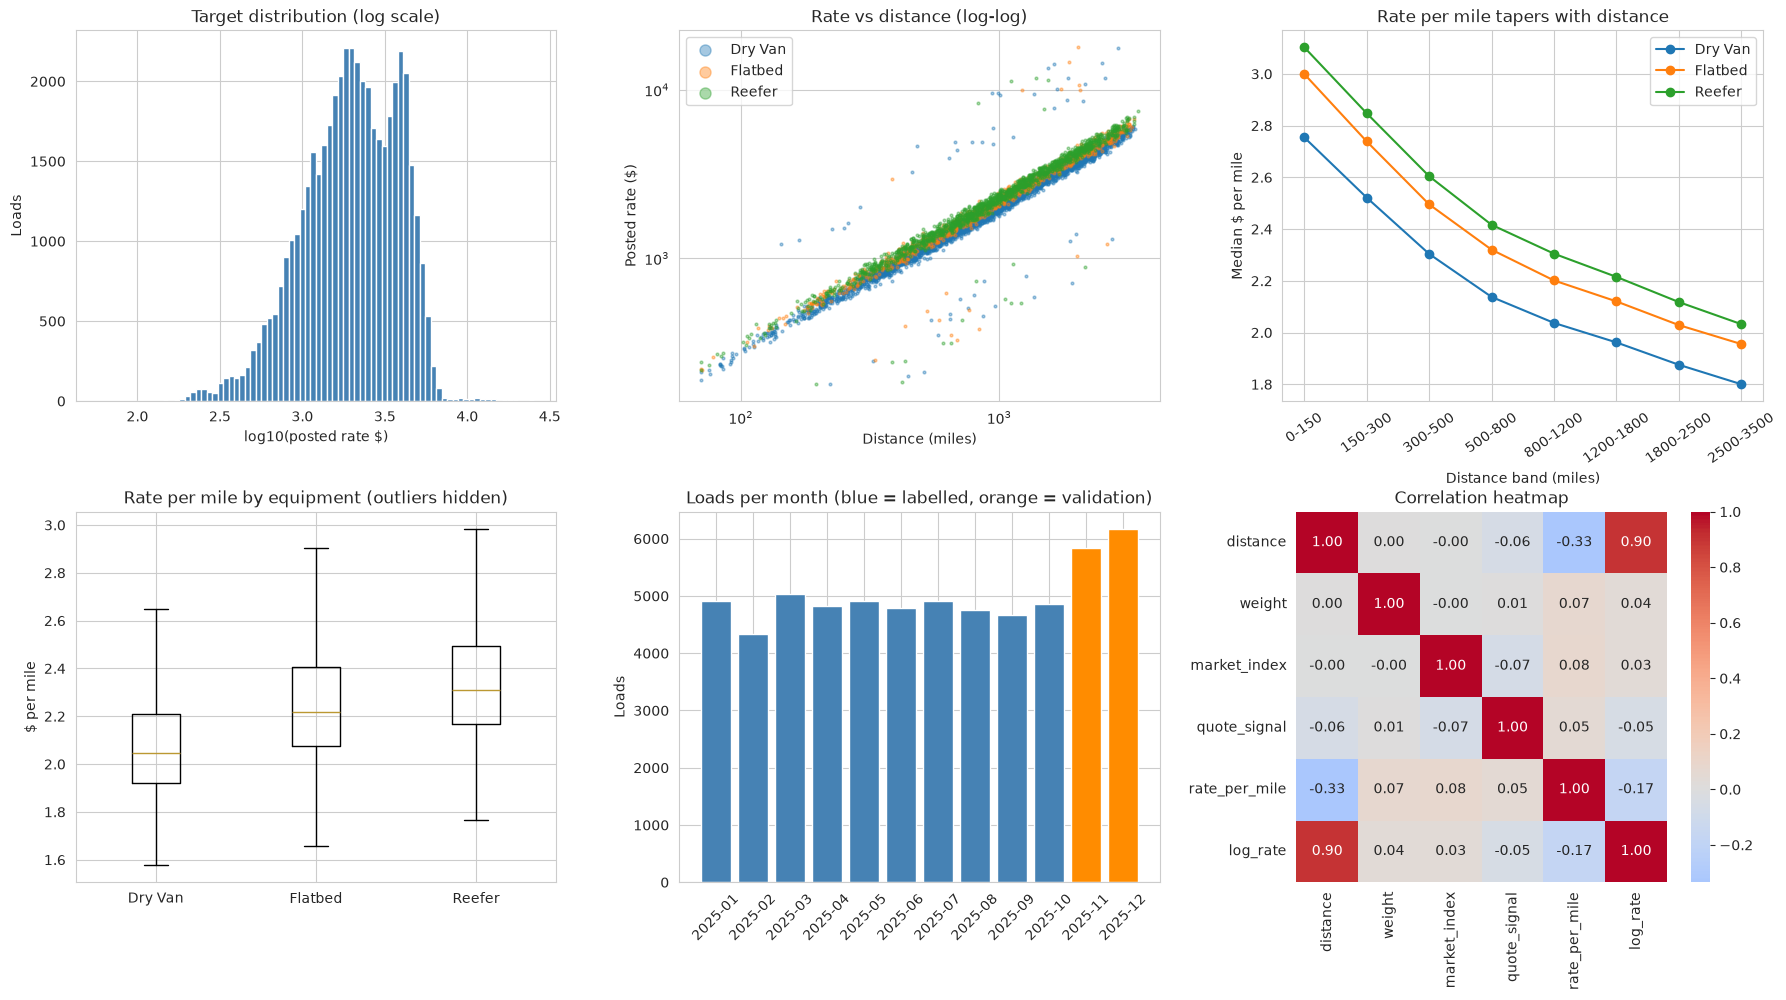

✅ Figure saved: outputs/figures/01_eda_overview.png


In [6]:
"""
Phase 2: Comprehensive Visualization Suite

Demonstrates: Multiple visualization types for thorough EDA
From Lecture: 4 (EDA)
"""

sample = train.sample(6000, random_state=RANDOM_SEED)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Target distribution (log scale)
ax = axes[0, 0]
ax.hist(np.log10(train['posted_rate']), bins=80, color='steelblue', edgecolor='white')
ax.set_xlabel('log10(posted rate $)')
ax.set_ylabel('Loads')
ax.set_title('Target distribution (log scale)')

# 2. Rate vs distance
ax = axes[0, 1]
for eq, grp in sample.groupby('equipment'):
    ax.scatter(grp['distance'], grp['posted_rate'], s=4, alpha=0.4, label=eq, color=EQUIPMENT_COLORS[eq])
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Distance (miles)')
ax.set_ylabel('Posted rate ($)')
ax.set_title('Rate vs distance (log-log)')
ax.legend(markerscale=4)

# 3. Rate per mile tapers with distance
ax = axes[0, 2]
bins = [0, 150, 300, 500, 800, 1200, 1800, 2500, 3500]
banded = train.assign(band=pd.cut(train['distance'], bins))
median_rpm = banded.groupby(['band', 'equipment'], observed=True)['rate_per_mile'].median().unstack()
for eq in median_rpm.columns:
    ax.plot(range(len(median_rpm)), median_rpm[eq].values, marker='o', label=eq, color=EQUIPMENT_COLORS[eq])
ax.set_xticks(range(len(median_rpm)))
ax.set_xticklabels([f"{int(b.left)}-{int(b.right)}" for b in median_rpm.index], rotation=35)
ax.set_xlabel('Distance band (miles)')
ax.set_ylabel('Median $ per mile')
ax.set_title('Rate per mile tapers with distance')
ax.legend()

# 4. Rate per mile by equipment
ax = axes[1, 0]
order = ['Dry Van', 'Flatbed', 'Reefer']
ax.boxplot([train.loc[train['equipment'] == eq, 'rate_per_mile'] for eq in order], showfliers=False)
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(order)
ax.set_ylabel('$ per mile')
ax.set_title('Rate per mile by equipment (outliers hidden)')

# 5. Loads per month
ax = axes[1, 1]
counts = pd.concat([train_raw['date'], validation_raw['date']]).dt.to_period('M').value_counts().sort_index()
colors = ['steelblue' if p.month <= 10 else 'darkorange' for p in counts.index]
ax.bar([str(p) for p in counts.index], counts.values, color=colors)
ax.set_title('Loads per month (blue = labelled, orange = validation)')
ax.tick_params(axis='x', rotation=45)
ax.set_ylabel('Loads')

# 6. Correlation heatmap
ax = axes[1, 2]
heat = train[['distance', 'weight', 'market_index', 'quote_signal', 'rate_per_mile']].assign(
    log_rate=np.log(train['posted_rate']))
sns.heatmap(heat.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax, square=True)
ax.set_title('Correlation heatmap')

plt.tight_layout()
save_figure(fig, '01_eda_overview.png')
plt.show()
print("✅ Figure saved: outputs/figures/01_eda_overview.png")

**Key insights**
* Rate scales almost linearly with distance; **rate per mile falls with distance** (fixed costs are spread over more miles).
* **Reefer > Flatbed > Dry Van** per mile — equipment is a clear price driver.
* Volume is stable (~4,800 loads/month) and the validation months have ~6,000 loads each.

## 2.3 Outlier Detection

**Learning Connection:** Lecture 4 (EDA — Outlier Analysis)

Classic IQR and Z-score rules first. Because a "normal" rate per mile depends on distance and equipment, a **robust model-based check** is then used to find labels that are wrong *for their own load*.

🔍 OUTLIER ANALYSIS

1. IQR method (rate per mile)    : 1,634 outliers (3.40%)
2. Z-score method (|Z| > 3)      : 411 outliers (0.86%)
   ⚠️ These rules also flag legitimately expensive short hauls (mostly Reefer) -> too blunt.



3. Robust residual check (5-fold out-of-fold, 18s)
   Typical loads: 98% within ±5.2% of expectation
   🚩 Flagged label errors: 677 loads (1.41%)
      inflated : 340 loads, 2.3x - 5.4x the expected rate
      deflated : 337 loads, 2.3x - 5.9x below the expected rate
   Loads in the 'gap' (0.25 < |log residual| <= 0.5): 0 -> the threshold choice is not sensitive


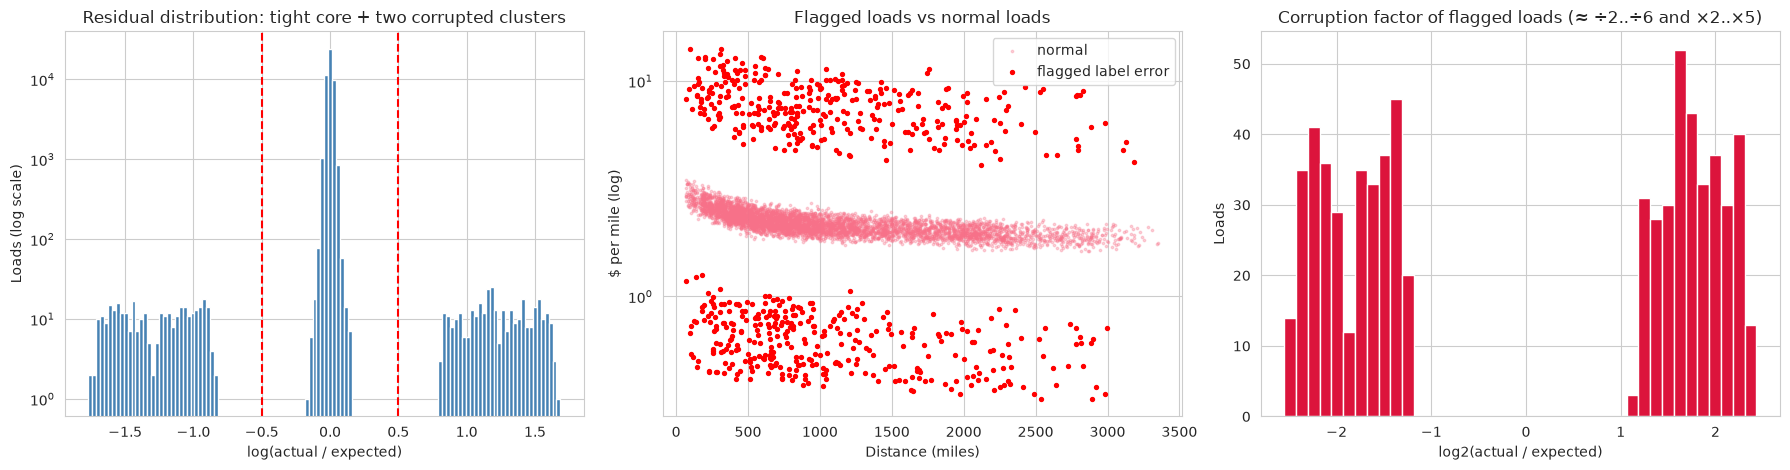


Examples of flagged loads:


,load_id,pickup,delivery,distance,equipment,date,posted_rate,expected_rate
50,TR-000051,Los Angeles,Green Bay,2202.5,Reefer,2025-01-01,1243.45,4182.06
190,TR-000191,Tampa,Milwaukee,919.8,Dry Van,2025-01-02,704.89,1815.47
294,TR-000295,Greensboro,Syracuse,685.6,Dry Van,2025-01-02,518.31,1346.65
388,TR-000389,Corpus Christi,Chattanooga,823.0,Flatbed,2025-01-03,5485.49,1809.34
439,TR-000440,Richmond,Charleston,394.9,Dry Van,2025-01-03,276.27,802.84
469,TR-000470,Phoenix,Jacksonville,2154.3,Dry Van,2025-01-04,10854.69,3731.14
508,TR-000509,Las Vegas,Grand Rapids,1976.4,Flatbed,2025-01-04,699.41,3667.06
785,TR-000786,Kansas City,Charleston,861.5,Dry Van,2025-01-06,4587.83,1646.66


In [7]:
"""
Phase 2: Outlier Detection and Analysis

Demonstrates: IQR method, Z-score method, robust model-based residuals
From Lecture: 4 (EDA)
"""

print("=" * 70)
print("🔍 OUTLIER ANALYSIS")
print("=" * 70)

# 1. Classic rules on rate per mile
rpm = train['rate_per_mile']
q1, q3 = rpm.quantile([0.25, 0.75])
iqr = q3 - q1
iqr_outliers = ((rpm < q1 - 1.5 * iqr) | (rpm > q3 + 1.5 * iqr)).sum()
z_outliers = (np.abs(stats.zscore(rpm)) > 3).sum()
print(f"\n1. IQR method (rate per mile)    : {iqr_outliers:,} outliers ({100 * iqr_outliers / len(train):.2f}%)")
print(f"2. Z-score method (|Z| > 3)      : {z_outliers:,} outliers ({100 * z_outliers / len(train):.2f}%)")
print("   ⚠️ These rules also flag legitimately expensive short hauls (mostly Reefer) -> too blunt.")

# 2. Robust model-based detection (out-of-fold, absolute-error loss = robust to the outliers themselves)
def quick_features(df):
    out = pd.DataFrame(index=df.index)
    out['log_distance'] = np.log(df['distance'])
    out['haversine'] = haversine_miles(df['pickup_lat'], df['pickup_lon'], df['delivery_lat'], df['delivery_lon'])
    for col in ['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon']:
        out[col] = df[col]
    out['equipment_code'] = df['equipment'].map({'Dry Van': 0, 'Reefer': 1, 'Flatbed': 2})
    out['weight_abs'] = df['weight'].abs()              # NaN allowed - handled natively by HistGB
    out['day_index'] = (df['date'] - START_DATE).dt.days
    return out

start = time.time()
robust_model = HistGradientBoostingRegressor(loss='absolute_error', max_iter=500, learning_rate=0.1,
                                             max_leaf_nodes=63, random_state=RANDOM_SEED)
oof_log_pred = cross_val_predict(robust_model, quick_features(train), np.log(train['posted_rate']),
                                 cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED))
train['log_residual'] = np.log(train['posted_rate']) - oof_log_pred
train['label_error'] = train['log_residual'].abs() > LABEL_ERROR_THRESHOLD
flagged = train[train['label_error']]
factor = np.exp(flagged['log_residual'])

print(f"\n3. Robust residual check (5-fold out-of-fold, {time.time() - start:.0f}s)")
print(f"   Typical loads: 98% within ±{100 * (np.exp(train.loc[~train['label_error'], 'log_residual'].abs().quantile(0.98)) - 1):.1f}% of expectation")
print(f"   🚩 Flagged label errors: {len(flagged):,} loads ({100 * len(flagged) / len(train):.2f}%)")
print(f"      inflated : {(factor > 1).sum():,} loads, {factor[factor > 1].min():.1f}x - {factor[factor > 1].max():.1f}x the expected rate")
print(f"      deflated : {(factor < 1).sum():,} loads, {1 / factor[factor < 1].max():.1f}x - {1 / factor[factor < 1].min():.1f}x below the expected rate")
in_gap = int(((train['log_residual'].abs() > 0.25) & (~train['label_error'])).sum())
print(f"   Loads in the 'gap' (0.25 < |log residual| <= {LABEL_ERROR_THRESHOLD}): {in_gap} "
      f"-> the threshold choice is not sensitive")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
ax = axes[0]
ax.hist(train['log_residual'], bins=120, color='steelblue')
ax.set_yscale('log')
for thr in (-LABEL_ERROR_THRESHOLD, LABEL_ERROR_THRESHOLD):
    ax.axvline(thr, color='red', linestyle='--')
ax.set_xlabel('log(actual / expected)')
ax.set_ylabel('Loads (log scale)')
ax.set_title('Residual distribution: tight core + two corrupted clusters')

ax = axes[1]
ok = train[~train['label_error']].sample(5000, random_state=RANDOM_SEED)
ax.scatter(ok['distance'], ok['rate_per_mile'], s=3, alpha=0.3, label='normal')
ax.scatter(flagged['distance'], flagged['rate_per_mile'], s=8, color='red', label='flagged label error')
ax.set_yscale('log')
ax.set_xlabel('Distance (miles)')
ax.set_ylabel('$ per mile (log)')
ax.set_title('Flagged loads vs normal loads')
ax.legend()

ax = axes[2]
ax.hist(np.log2(factor), bins=40, color='crimson')
ax.set_xlabel('log2(actual / expected)')
ax.set_ylabel('Loads')
ax.set_title('Corruption factor of flagged loads (≈ ÷2..÷6 and ×2..×5)')
plt.tight_layout()
save_figure(fig, '02_label_errors.png')
plt.show()

print("\nExamples of flagged loads:")
display(flagged.assign(expected_rate=np.exp(oof_log_pred[train['label_error'].values]).round(2))
        [['load_id', 'pickup', 'delivery', 'distance', 'equipment', 'date', 'posted_rate', 'expected_rate']].head(8))
print("=" * 70)

**Interpretation**
* 98.6% of loads sit within a few percent of a robust expectation; **~1.4% are 2–6× off** — with an empty gap in between.
* That bimodal shape is the signature of **data-entry errors** (e.g. keying or unit mistakes), not of genuinely expensive loads.
* Decision: **remove these labels from training** (they would bias any squared-error model) and evaluate on clean labels — metrics including them are also reported for transparency.

## 2.4 Signal Stability Over Time ⭐ (critical finding)

**Learning Connection:** Lecture 4 (EDA) & Lecture 6 (why the split must respect time)

The validation loads are *future* months, so every feature must keep the **same relationship with the rate over time**. Two signals do not.

### 2.4.1 `quote_signal` switches regime every month

🔍 quote_signal vs actual rate per mile - by month (clean labels)


,loads,"corr(quote, rate/mile)",slope,intercept,regime
month,,,,,
Jan,4837,0.996,1.000,-0.001,DIRECT (quote ≈ rate/mile)
Feb,4280,0.996,0.999,0.001,DIRECT (quote ≈ rate/mile)
Mar,4965,0.997,1.001,-0.002,DIRECT (quote ≈ rate/mile)
Apr,4753,-0.993,-1.002,4.154,INVERTED (quote ≈ 4.15 - rate/mile)
May,4851,-0.994,-1.000,4.150,INVERTED (quote ≈ 4.15 - rate/mile)
Jun,4720,0.997,0.999,0.002,DIRECT (quote ≈ rate/mile)
Jul,4847,-0.994,-0.999,4.147,INVERTED (quote ≈ 4.15 - rate/mile)
Aug,4691,-0.020,-0.017,2.090,NOISE (unrelated)
Sep,4606,0.997,1.000,0.000,DIRECT (quote ≈ rate/mile)


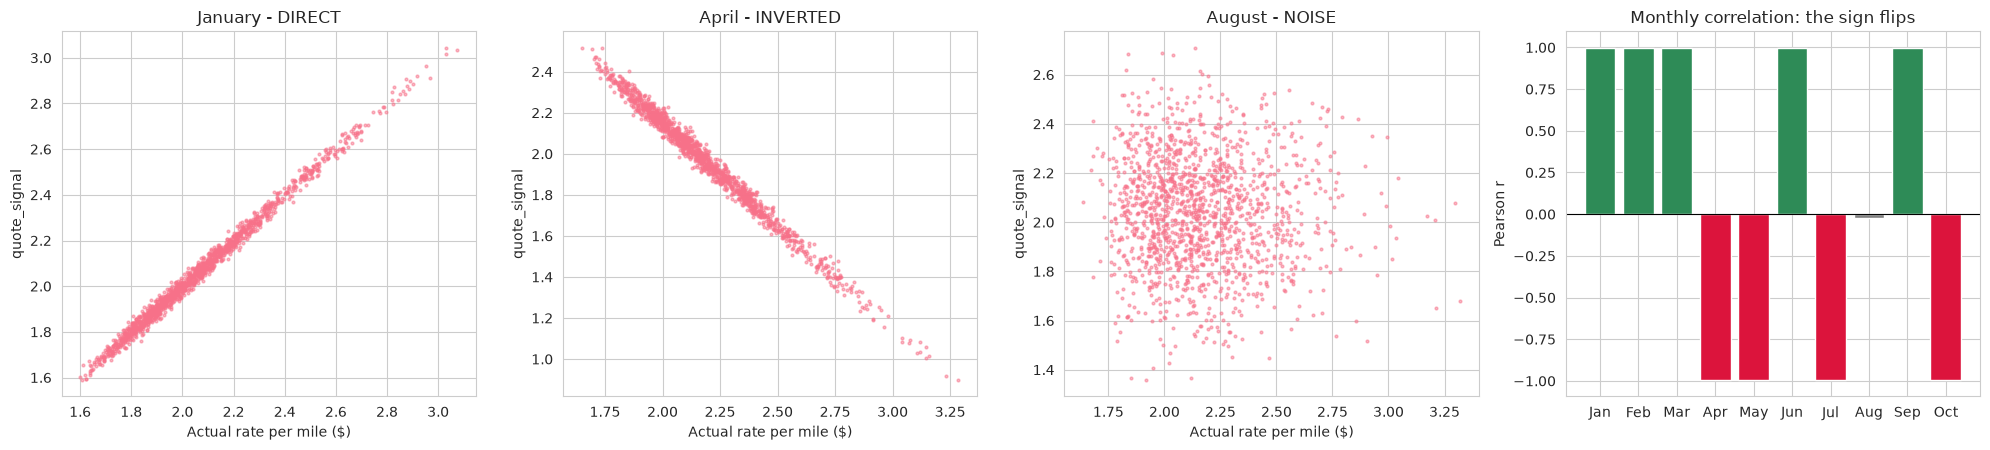

➡️  In DIRECT months quote_signal is a near-copy of the label (a leak); in INVERTED months it is
    a mirror image; in August it is pure noise. Its meaning in Nov-Dec cannot be assumed.
    Decision: EXCLUDE quote_signal (re-checked on the validation months, label-free, in Part 5).


In [8]:
"""
Phase 2: Stability of quote_signal across months

Demonstrates: Leakage / concept-drift detection with grouped analysis
From Lecture: 4 (EDA), 6 (Validation)
"""

clean_eda = train[~train['label_error']].copy()
rows = []
for month, grp in clean_eda.groupby('month'):
    slope, intercept = np.polyfit(grp['rate_per_mile'], grp['quote_signal'], 1)
    corr = np.corrcoef(grp['rate_per_mile'], grp['quote_signal'])[0, 1]
    if corr > 0.5:
        regime = 'DIRECT   (quote ≈ rate/mile)'
    elif corr < -0.5:
        regime = 'INVERTED (quote ≈ 4.15 - rate/mile)'
    else:
        regime = 'NOISE    (unrelated)'
    rows.append({'month': pd.Timestamp(2025, int(month), 1).strftime('%b'), 'loads': len(grp),
                 'corr(quote, rate/mile)': corr, 'slope': slope, 'intercept': intercept, 'regime': regime})
quote_regimes = pd.DataFrame(rows).set_index('month')

print("=" * 70)
print("🔍 quote_signal vs actual rate per mile - by month (clean labels)")
print("=" * 70)
display(quote_regimes.round(3))

fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, (month, title) in zip(axes[:3], [(1, 'January - DIRECT'), (4, 'April - INVERTED'), (8, 'August - NOISE')]):
    grp = clean_eda[clean_eda['month'] == month].sample(1500, random_state=RANDOM_SEED)
    ax.scatter(grp['rate_per_mile'], grp['quote_signal'], s=4, alpha=0.5)
    ax.set_xlabel('Actual rate per mile ($)')
    ax.set_ylabel('quote_signal')
    ax.set_title(title)
ax = axes[3]
bar_colors = ['seagreen' if c > 0.5 else ('crimson' if c < -0.5 else 'grey') for c in quote_regimes['corr(quote, rate/mile)']]
ax.bar(quote_regimes.index, quote_regimes['corr(quote, rate/mile)'], color=bar_colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Monthly correlation: the sign flips')
ax.set_ylabel('Pearson r')
plt.tight_layout()
save_figure(fig, '03_quote_signal_regimes.png')
plt.show()

print("➡️  In DIRECT months quote_signal is a near-copy of the label (a leak); in INVERTED months it is")
print("    a mirror image; in August it is pure noise. Its meaning in Nov-Dec cannot be assumed.")
print("    Decision: EXCLUDE quote_signal (re-checked on the validation months, label-free, in Part 5).")

### 2.4.2 Market level, `market_index` and the quarter-end effect

To see how prices move **over time**, a model *without any time feature* is fitted on the clean loads; the average residual per day is the **daily market rate level** (lane, distance, equipment and weight effects removed).

📈 MONTHLY MARKET RATE LEVEL vs MARKET INDEX


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct
rate_level_pct,-4.750,-3.530,-0.282,0.100,2.2,4.489,1.752,-0.978,0.445,0.764
market_index,0.927,0.997,1.074,1.209,1.3,1.280,1.200,0.980,0.893,0.957


Validation market_index: Nov=0.919, Dec=0.935

Jan-Aug : rate level moves 0.19% per 1% of market_index (corr = 0.88)
Sep-Oct : market_index fell to 0.925 (Jan level) but the rate level stayed at +0.6% -> the co-movement breaks down


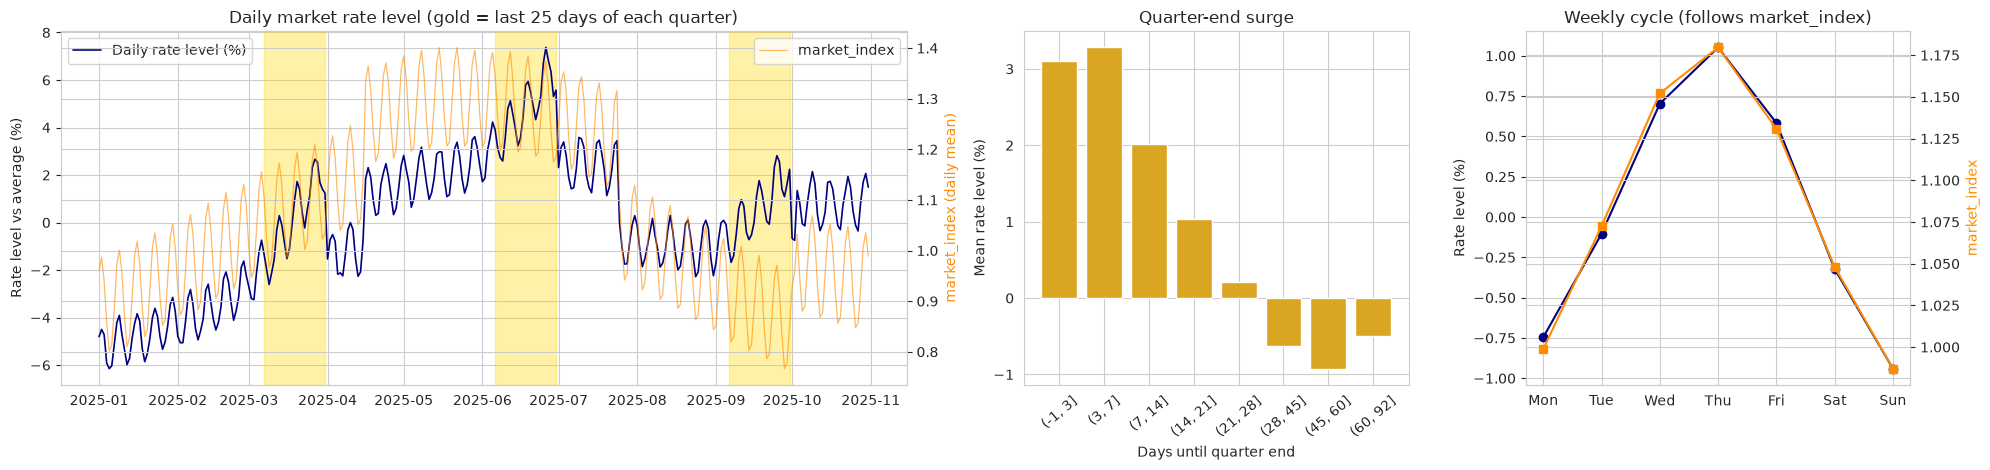

In [9]:
"""
Phase 2: Daily market rate level vs market_index; calendar effects

Demonstrates: Time-series EDA, decomposition of a target into lane price x market level
From Lecture: 4 (EDA), 5 (Feature Engineering ideas)
"""

static_cols = ['log_distance', 'haversine', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon',
               'equipment_code', 'weight_abs']
static_features = quick_features(clean_eda)[static_cols]
static_model = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.1, max_leaf_nodes=63, random_state=RANDOM_SEED)
static_model.fit(static_features, np.log(clean_eda['posted_rate']))
clean_eda['level_residual'] = np.log(clean_eda['posted_rate']) - static_model.predict(static_features)

daily = clean_eda.groupby('date').agg(rate_level=('level_residual', 'mean'),
                                      market_index=('market_index', 'mean'))
daily['rate_level_pct'] = 100 * (np.exp(daily['rate_level'] - daily['rate_level'].mean()) - 1)
daily['days_to_qe'] = days_to_quarter_end(daily.index).values
daily['weekday'] = daily.index.dayofweek

monthly = daily.groupby(daily.index.month).agg(rate_level_pct=('rate_level_pct', 'mean'),
                                               market_index=('market_index', 'mean'))
monthly.index = [pd.Timestamp(2025, int(m), 1).strftime('%b') for m in monthly.index]

print("=" * 70)
print("📈 MONTHLY MARKET RATE LEVEL vs MARKET INDEX")
print("=" * 70)
display(monthly.round(3).T)
validation_mi = validation_raw.groupby(validation_raw['date'].dt.month)['market_index'].mean()
print(f"Validation market_index: Nov={validation_mi.get(11, np.nan):.3f}, Dec={validation_mi.get(12, np.nan):.3f}")

early = daily[daily.index < HOLDOUT_START]
late = daily[daily.index >= HOLDOUT_START]
slope_early = np.polyfit(np.log(early['market_index']), early['rate_level'], 1)[0]
print(f"\nJan-Aug : rate level moves {slope_early:.2f}% per 1% of market_index (corr = "
      f"{np.corrcoef(np.log(early['market_index']), early['rate_level'])[0, 1]:.2f})")
print(f"Sep-Oct : market_index fell to {late['market_index'].mean():.3f} (Jan level) but the rate level stayed at "
      f"{late['rate_level_pct'].mean():+.1f}% -> the co-movement breaks down")

ramp_profile = daily.groupby(pd.cut(daily['days_to_qe'], [-1, 3, 7, 14, 21, 28, 45, 60, 92]), observed=True)['rate_level_pct'].mean()
weekday_profile = daily.groupby('weekday')[['rate_level_pct', 'market_index']].mean()

fig, axes = plt.subplots(1, 3, figsize=(20, 4.8), gridspec_kw={'width_ratios': [2.2, 1, 1]})
ax = axes[0]
ax.plot(daily.index, daily['rate_level_pct'], color='navy', linewidth=1.2, label='Daily rate level (%)')
for q_end in pd.to_datetime(['2025-03-31', '2025-06-30', '2025-09-30']):
    ax.axvspan(q_end - pd.Timedelta(days=24), q_end, color='gold', alpha=0.35)
ax.set_ylabel('Rate level vs average (%)')
ax.set_title('Daily market rate level (gold = last 25 days of each quarter)')
ax2 = ax.twinx()
ax2.plot(daily.index, daily['market_index'], color='darkorange', alpha=0.6, linewidth=0.9, label='market_index')
ax2.set_ylabel('market_index (daily mean)', color='darkorange')
ax.legend(loc='upper left')
ax2.legend(loc='upper right')

ax = axes[1]
ax.bar([str(b) for b in ramp_profile.index], ramp_profile.values, color='goldenrod')
ax.set_xlabel('Days until quarter end')
ax.set_ylabel('Mean rate level (%)')
ax.set_title('Quarter-end surge')
ax.tick_params(axis='x', rotation=40)

ax = axes[2]
names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
ax.plot(names, weekday_profile['rate_level_pct'], marker='o', color='navy', label='rate level (%)')
ax.set_ylabel('Rate level (%)')
ax3 = ax.twinx()
ax3.plot(names, weekday_profile['market_index'], marker='s', color='darkorange', label='market_index')
ax3.set_ylabel('market_index', color='darkorange')
ax.set_title('Weekly cycle (follows market_index)')
plt.tight_layout()
save_figure(fig, '04_market_level.png')
plt.show()

### ✅ What the signal-stability analysis tells us

| Signal | What happens | Modelling decision |
|--------|--------------|--------------------|
| `quote_signal` | Direct copy of rate/mile in Jan–Mar, Jun, Sep; **mirror image** in Apr, May, Jul, Oct; **noise** in Aug | **Excluded** — a model would learn a relationship that flips without warning |
| `market_index` (load level) | ±2.5% noise around a **daily** market level; strong Wed–Thu peak / Sun–Mon dip | Use the **daily average** market index |
| `market_index` vs rates | Co-moves Jan–Aug, but rates stay high in Sep–Oct while the index falls | Let it enter **only as a small, linear elasticity** next to a **trend** — never as a free tree feature |
| Calendar | Rates climb ~4% over the **last ~25 days of every quarter** (Mar, Jun, Sep) | Add a **quarter-end ramp** feature → December (a quarter end) is covered |

These findings drive the model design: **rate = lane price × market level**.

---

# PART 3: PREPROCESSING & FEATURE ENGINEERING

---

## 3.1 Data Cleaning

**Learning Connection:** Lecture 3 (Data Preprocessing Fundamentals)

Every fix is either applied **inside the pipeline** (so validation and December inputs get exactly the same treatment) or is a documented removal of bad labels. Two lookup tables are built from *features only* (no labels): city coordinates and the daily market index.

In [10]:
"""
Phase 3: Data Cleaning and lookup tables

Demonstrates: Treating each data-quality issue explicitly, leakage-free lookups
From Lecture: 3 (Preprocessing)
"""

# --- 1. Remove corrupted labels (identified in Section 2.3) -------------------------------
dev_all = train_raw.copy()
dev_all['label_error'] = train['label_error'].values
dev_clean = dev_all[~dev_all['label_error']].reset_index(drop=True)

# --- 2. City coordinate lookup (train + validation features) -----------------------------
def build_city_table(*frames):
    parts = []
    for frame in frames:
        for side in ('pickup', 'delivery'):
            part = frame[[side, f'{side}_lat', f'{side}_lon']].rename(
                columns={side: 'city', f'{side}_lat': 'lat', f'{side}_lon': 'lon'})
            parts.append(part)
    return pd.concat(parts, ignore_index=True).groupby('city')[['lat', 'lon']].median()

CITY_COORDS = build_city_table(train_raw, validation_raw)

# --- 3. Daily market index lookup (train + validation features, no labels) ----------------
MARKET_DAILY = (pd.concat([train_raw[['date', 'market_index']], validation_raw[['date', 'market_index']]])
                .groupby('date')['market_index'].mean())

# --- 4. Data-quality log ---------------------------------------------------------------
dq_log = pd.DataFrame([
    ['Corrupted posted_rate labels (2-6x off)', f"{int(dev_all['label_error'].sum()):,}", '-',
     'Removed from training & clean evaluation'],
    ['Negative weight (sign error)', f"{int((train_raw['weight'] < 0).sum()):,}", f"{int((validation_raw['weight'] < 0).sum()):,}",
     'Absolute value (pipeline)'],
    ['Missing weight', f"{int(train_raw['weight'].isna().sum()):,}", f"{int(validation_raw['weight'].isna().sum()):,}",
     'Median weight of the same equipment (learned on training folds)'],
    ['Missing market_index', f"{int(train_raw['market_index'].isna().sum()):,}", f"{int(validation_raw['market_index'].isna().sum()):,}",
     'Not needed: daily market index used'],
    ['market_index load-level noise / drift', 'all', 'all', 'Daily average + linear elasticity with trend'],
    ['quote_signal regime flips by month', 'all', 'all', 'Excluded from the model'],
    ['Cities only in validation', '-', f"{int(new_city_rows.sum()):,}", 'Coordinates instead of city IDs'],
    ['Weight cap 47,500 / floor 5,000; distance floor 70 mi', f"{int((train_raw['weight'].abs() == 47500).sum()):,}", '-',
     'Valid business limits - kept'],
    ['December inputs lack coordinates / market data', '-', '31 rows', 'Filled from the lookup tables'],
], columns=['Issue', 'Dev rows', 'Validation rows', 'Treatment'])

print("=" * 70)
print("🧹 DATA CLEANING SUMMARY")
print("=" * 70)
display(dq_log)
print(f"Development rows: {len(dev_all):,} -> clean rows used for modelling: {len(dev_clean):,}")
print(f"City lookup     : {len(CITY_COORDS)} cities | Daily market lookup: {len(MARKET_DAILY)} days "
      f"({MARKET_DAILY.index.min().date()} -> {MARKET_DAILY.index.max().date()})")
dq_log.to_csv(REPORT_DIR / 'data_quality_log.csv', index=False)

🧹 DATA CLEANING SUMMARY


,Issue,Dev rows,Validation rows,Treatment
0,Corrupted posted_rate labels (2-6x off),677,-,Removed from training & clean evaluation
1,Negative weight (sign error),292,145,Absolute value (pipeline)
2,Missing weight,300,165,Median weight of the same equipment (learned o...
3,Missing market_index,374,249,Not needed: daily market index used
4,market_index load-level noise / drift,all,all,Daily average + linear elasticity with trend
5,quote_signal regime flips by month,all,all,Excluded from the model
6,Cities only in validation,-,"1,447",Coordinates instead of city IDs
7,"Weight cap 47,500 / floor 5,000; distance floo...","1,204",-,Valid business limits - kept
8,December inputs lack coordinates / market data,-,31 rows,Filled from the lookup tables


Development rows: 48,000 -> clean rows used for modelling: 47,323
City lookup     : 72 cities | Daily market lookup: 365 days (2025-01-01 -> 2025-12-31)


## 3.2 Train–Test Split (time-based)

**Learning Connection:** Lecture 6 (Train-Test Split & Cross-Validation)

The real task is *train on Jan–Oct → predict Nov–Dec* (a 2-month-ahead forecast). The development split mirrors it exactly:

* **Development set:** Jan 1 – Aug 31 (clean labels) → fitting, model comparison and tuning
* **Holdout set:** Sep 1 – Oct 31 (clean labels) → touched **once**, for the final unbiased estimate
* **Tuning folds inside development (expanding window, 2-month horizon):** Jan–Apr → May–Jun and Jan–Jun → Jul–Aug

A random split would put every month on both sides of the split and hide drift such as the `quote_signal` regime changes — Section 4.3 measures exactly how misleading that would be.

📊 TIME-BASED TRAIN-TEST SPLIT

Development set : 37,944 loads  2025-01-01 -> 2025-08-31
Holdout set     :  9,379 loads  2025-09-01 -> 2025-10-31 (+144 flagged labels kept aside)
Validation set  : 12,000 loads  2025-11-01 -> 2025-12-31 (no labels)
Tuning fold 1   : train 18,835 (2025-01-01 -> 2025-04-30) | validate 9,571 (2025-05-01 -> 2025-06-30)
Tuning fold 2   : train 28,406 (2025-01-01 -> 2025-06-30) | validate 9,538 (2025-07-01 -> 2025-08-31)

Target distribution comparison:
  Development - mean $2,344  median $2,028  std $1,348
  Holdout     - mean $2,360  median $2,045  std $1,375
  Rate per mile - dev 2.141  vs holdout 2.162


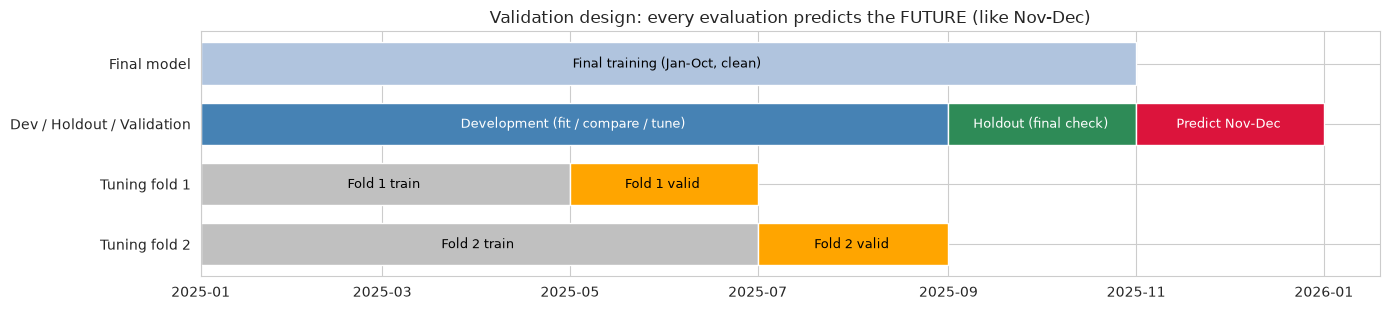


✅ Time-based split complete - no future information leaks into training


In [11]:
"""
Phase 3: Proper Time-Based Train-Test Split

Demonstrates: Temporal validation, leakage prevention, inner time-series folds
From Lecture: 6 (Train-Test Split)
"""

dev = dev_clean[dev_clean['date'] < HOLDOUT_START].reset_index(drop=True)
holdout = dev_clean[dev_clean['date'] >= HOLDOUT_START].reset_index(drop=True)
holdout_all = dev_all[dev_all['date'] >= HOLDOUT_START].reset_index(drop=True)   # incl. flagged labels

X_dev, y_dev = dev[FEATURE_COLUMNS], dev[TARGET]
X_hold, y_hold = holdout[FEATURE_COLUMNS], holdout[TARGET]


def month_fold(frame, train_end, valid_end):
    """Expanding-window fold: train on everything before train_end, validate on [train_end, valid_end)."""
    train_idx = np.where(frame['date'] < train_end)[0]
    valid_idx = np.where((frame['date'] >= train_end) & (frame['date'] < valid_end))[0]
    return train_idx, valid_idx


TIME_FOLDS = [month_fold(dev, pd.Timestamp('2025-05-01'), pd.Timestamp('2025-07-01')),
              month_fold(dev, pd.Timestamp('2025-07-01'), pd.Timestamp('2025-09-01'))]

print("=" * 70)
print("📊 TIME-BASED TRAIN-TEST SPLIT")
print("=" * 70)
print(f"\nDevelopment set : {len(dev):>6,} loads  {dev['date'].min().date()} -> {dev['date'].max().date()}")
print(f"Holdout set     : {len(holdout):>6,} loads  {holdout['date'].min().date()} -> {holdout['date'].max().date()} "
      f"(+{len(holdout_all) - len(holdout)} flagged labels kept aside)")
print(f"Validation set  : {len(validation_raw):>6,} loads  {validation_raw['date'].min().date()} -> "
      f"{validation_raw['date'].max().date()} (no labels)")
for i, (tr_idx, va_idx) in enumerate(TIME_FOLDS, 1):
    print(f"Tuning fold {i}   : train {len(tr_idx):,} ({dev['date'].iloc[tr_idx].min().date()} -> "
          f"{dev['date'].iloc[tr_idx].max().date()}) | validate {len(va_idx):,} "
          f"({dev['date'].iloc[va_idx].min().date()} -> {dev['date'].iloc[va_idx].max().date()})")

print("\nTarget distribution comparison:")
for name, target in [('Development', y_dev), ('Holdout', y_hold)]:
    print(f"  {name:11s} - mean ${target.mean():,.0f}  median ${target.median():,.0f}  std ${target.std():,.0f}")
print(f"  Rate per mile - dev {np.median(y_dev / dev['distance']):.3f}  vs holdout {np.median(y_hold / holdout['distance']):.3f}")

# Timeline figure
fig, ax = plt.subplots(figsize=(14, 3.2))
segments = [
    ('Final training (Jan-Oct, clean)', '2025-01-01', '2025-10-31', 'lightsteelblue', 4),
    ('Development (fit / compare / tune)', '2025-01-01', '2025-08-31', 'steelblue', 3),
    ('Holdout (final check)', '2025-09-01', '2025-10-31', 'seagreen', 3),
    ('Fold 1 train', '2025-01-01', '2025-04-30', 'silver', 2), ('Fold 1 valid', '2025-05-01', '2025-06-30', 'orange', 2),
    ('Fold 2 train', '2025-01-01', '2025-06-30', 'silver', 1), ('Fold 2 valid', '2025-07-01', '2025-08-31', 'orange', 1),
    ('Predict Nov-Dec', '2025-11-01', '2025-12-31', 'crimson', 3),
]
dark_colors = {'steelblue', 'seagreen', 'crimson'}
for label, start_, end_, color, y in segments:
    s, e = pd.Timestamp(start_), pd.Timestamp(end_)
    ax.barh(y, (e - s).days + 1, left=s, color=color, edgecolor='white', height=0.7)
    ax.text(s + (e - s) / 2, y, label, ha='center', va='center', fontsize=9,
            color='white' if color in dark_colors else 'black')
ax.set_yticks([1, 2, 3, 4])
ax.set_yticklabels(['Tuning fold 2', 'Tuning fold 1', 'Dev / Holdout / Validation', 'Final model'])
ax.set_title('Validation design: every evaluation predicts the FUTURE (like Nov-Dec)')
plt.tight_layout()
save_figure(fig, '05_time_split.png')
plt.show()
print("\n✅ Time-based split complete - no future information leaks into training")

## 3.3 Custom Feature Engineering

**Learning Connection:** Lecture 5 (Feature Engineering & Selection) and Lecture 11 (custom transformers)

`FreightFeatureEngineer` is a scikit-learn transformer, so every step is learned on the training fold only and applied identically to holdout, validation and December rows.

| Feature group | Features | Why |
|---------------|----------|-----|
| Distance | `distance`, `log_distance`, `haversine_miles`, `circuity` | Rate ≈ distance × tapering rate/mile; circuity = road miles ÷ straight-line miles |
| Geography | pickup / delivery lat & lon, `lat_delta`, `lon_delta` | Regional pricing and lane direction; generalises to unseen cities |
| Load | `weight_lbs` (sign fixed, imputed by equipment), `is_reefer`, `is_flatbed` | Equipment premium, weight effect |
| Market level | `day_index` (trend), `log_market_index_day`, `quarter_end_ramp` | Time effects — used only by the linear market-level stage |

In [12]:
"""
Phase 3: Feature Engineering

Demonstrates: Domain knowledge, ratio features, geography, calendar features in a custom transformer
From Lecture: 5 (Feature Engineering), 11 (Pipelines)
"""

LEVEL_COLUMNS = ('day_index', 'log_market_index_day', 'quarter_end_ramp')


class FreightFeatureEngineer(BaseEstimator, TransformerMixin):
    """
    Custom transformer for the freight dataset.

    Creates domain-specific features from the raw load columns:
    - distance, geography and lane-direction features (work for cities never seen in training)
    - cleaned weight (sign errors fixed, missing values = median weight of the same equipment)
    - equipment one-hot flags
    - market-level features: day index (trend), log daily market index, quarter-end ramp

    feature_set='production' (default)  : the features above.
    feature_set='production+signals'    : the features above + raw market_index + raw quote_signal.
    feature_set='naive'                  : the "use every provided column as-is" approach - raw
                                           market_index, raw quote_signal and day of week instead of
                                           the market-level features.
    The last two exist only for the comparison in Part 4.
    """

    def __init__(self, market_table=None, start_date='2025-01-01', ramp_days=25, feature_set='production'):
        self.market_table = market_table
        self.start_date = start_date
        self.ramp_days = ramp_days
        self.feature_set = feature_set

    def _clean_inputs(self, X):
        df = pd.DataFrame(X).copy()
        df['date'] = pd.to_datetime(df['date'])
        df['equipment'] = df['equipment'].astype(str).str.strip()
        df['weight'] = pd.to_numeric(df['weight'], errors='coerce').abs()      # sign errors -> magnitude
        if 'market_index' not in df:
            df['market_index'] = np.nan
        return df

    def _engineer(self, df):
        out = pd.DataFrame(index=df.index)
        distance = df['distance'].astype(float).clip(lower=1.0)
        out['distance'] = distance
        out['log_distance'] = np.log(distance)
        out['haversine_miles'] = haversine_miles(df['pickup_lat'], df['pickup_lon'],
                                                 df['delivery_lat'], df['delivery_lon'])
        out['circuity'] = distance / np.clip(out['haversine_miles'], 5.0, None)
        for col in ['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon']:
            out[col] = df[col].astype(float)
        out['lat_delta'] = out['delivery_lat'] - out['pickup_lat']
        out['lon_delta'] = out['delivery_lon'] - out['pickup_lon']

        weight_fill = df['equipment'].map(self.weight_median_by_equipment_).astype(float).fillna(self.weight_median_)
        out['weight_lbs'] = df['weight'].fillna(weight_fill)
        out['is_reefer'] = (df['equipment'] == 'Reefer').astype(float)
        out['is_flatbed'] = (df['equipment'] == 'Flatbed').astype(float)

        if self.feature_set == 'naive':                     # every provided column, as given
            out['market_index_raw'] = df['market_index'].astype(float)
            out['quote_signal'] = df['quote_signal'].astype(float)
            out['day_of_week'] = df['date'].dt.dayofweek.astype(float)
            return out

        # Market-level features (identical for every load on the same day)
        if self.market_table is not None:
            market = df['date'].map(self.market_table).astype(float)
        else:
            market = pd.Series(np.nan, index=df.index)
        market = market.fillna(df['market_index'].astype(float)).fillna(self.market_median_)
        out['day_index'] = (df['date'] - pd.Timestamp(self.start_date)).dt.days.astype(float)
        out['log_market_index_day'] = np.log(market.clip(lower=0.05))
        dqe = days_to_quarter_end(df['date']).values
        out['quarter_end_ramp'] = np.clip(self.ramp_days - dqe, 0, None) / float(self.ramp_days)

        if self.feature_set == 'production+signals':
            out['market_index_raw'] = df['market_index'].astype(float)
            out['quote_signal'] = df['quote_signal'].astype(float)
        return out

    def fit(self, X, y=None):
        df = self._clean_inputs(X)
        self.weight_median_by_equipment_ = df.groupby('equipment')['weight'].median().to_dict()
        self.weight_median_ = float(df['weight'].median())
        if self.market_table is not None:
            self.market_median_ = float(pd.Series(self.market_table).median())
        else:
            self.market_median_ = float(df['market_index'].median())
        features = self._engineer(df)
        self.fill_values_ = features.median()
        self.feature_names_ = list(features.columns)
        return self

    def transform(self, X):
        check_is_fitted(self, 'fill_values_')
        features = self._engineer(self._clean_inputs(X))
        return features.fillna(self.fill_values_)[self.feature_names_]


# Test the transformer
engineer = FreightFeatureEngineer(market_table=MARKET_DAILY)
X_dev_engineered = engineer.fit_transform(X_dev)
X_hold_engineered = engineer.transform(X_hold)

print("=" * 70)
print("🔧 FEATURE ENGINEERING")
print("=" * 70)
print(f"\nRaw input columns   : {len(FEATURE_COLUMNS)} ({', '.join(FEATURE_COLUMNS)})")
print(f"Engineered features : {X_dev_engineered.shape[1]}")
print(f"  • Lane-price features   : {[c for c in engineer.feature_names_ if c not in LEVEL_COLUMNS]}")
print(f"  • Market-level features : {list(LEVEL_COLUMNS)}")
print(f"\nLearned imputation (training fold only): weight median by equipment = "
      f"{ {k: round(v) for k, v in engineer.weight_median_by_equipment_.items()} }")
print(f"Missing values after transform: dev={int(X_dev_engineered.isna().sum().sum())}, "
      f"holdout={int(X_hold_engineered.isna().sum().sum())}")

print("\nEngineered Feature Statistics:")
display(X_dev_engineered.describe().T[['mean', 'std', 'min', 'max']])

corr_with_target = X_dev_engineered.assign(log_rate=np.log(y_dev.values)).corr()['log_rate'].drop('log_rate')
print("Correlation with log(rate) - top features:")
print(corr_with_target.abs().sort_values(ascending=False).head(8).round(3))
print("=" * 70)

🔧 FEATURE ENGINEERING

Raw input columns   : 12 (pickup, delivery, pickup_lat, pickup_lon, delivery_lat, delivery_lon, distance, equipment, weight, date, market_index, quote_signal)
Engineered features : 16
  • Lane-price features   : ['distance', 'log_distance', 'haversine_miles', 'circuity', 'pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'lat_delta', 'lon_delta', 'weight_lbs', 'is_reefer', 'is_flatbed']
  • Market-level features : ['day_index', 'log_market_index_day', 'quarter_end_ramp']

Learned imputation (training fold only): weight median by equipment = {'Dry Van': 31433, 'Flatbed': 31521, 'Reefer': 31553}
Missing values after transform: dev=0, holdout=0

Engineered Feature Statistics:


,mean,std,min,max
distance,1136.9579,726.6644,70.0000,3439.8000
log_distance,6.8002,0.7383,4.2485,8.1432
haversine_miles,967.0794,629.0642,7.2652,2873.6526
circuity,1.1950,0.1531,1.0581,9.6349
pickup_lat,35.6387,4.3133,28.3576,44.3030
pickup_lon,-90.9559,13.4908,-121.6985,-69.5000
delivery_lat,35.6448,4.3183,28.3576,44.3030
delivery_lon,-90.8970,13.4701,-121.6985,-69.5000
lat_delta,0.0061,6.1360,-15.9453,15.9453
lon_delta,0.0589,19.1740,-52.1985,52.1985


Correlation with log(rate) - top features:
log_distance       0.993
distance           0.923
haversine_miles    0.923
circuity           0.278
delivery_lon       0.252
pickup_lon         0.248
delivery_lat       0.103
pickup_lat         0.096
Name: log_rate, dtype: float64


---

# PART 4: MODEL DEVELOPMENT & EVALUATION

---

## 4.1 Baseline Models

**Learning Connection:** Lecture 7 (Performance Metrics — Regression)

Every model is trained on **Jan–Aug** and scored on the **Sep–Oct holdout**. All learning models predict `log(rate)` (via `TransformedTargetRegressor`) because pricing is multiplicative.

* A **rate-per-mile heuristic** (median \$/mile by equipment × distance band) represents how a human might quote.
* The standard models all get the same engineered features: the lane features plus `day_index`, `log_market_index_day` and `quarter_end_ramp`.
* Two diagnostic variants show what happens if Section 2.4 is ignored:
  * `HistGB + raw quote & market signals` — the same features **plus** the raw load-level `market_index` and `quote_signal`.
  * `Naive HistGB (all raw columns)` — the typical first attempt: lane features + raw `market_index`, raw `quote_signal` and day of week, without the market-level features.

In [13]:
"""
Phase 4: Baseline Model Development and Comparison

Demonstrates: Multiple algorithms, consistent pipelines, metric selection
From Lectures: 7 (Regression Metrics), 11 (Pipelines)
"""

def log_target(model):
    """Fit on log(rate), predict in dollars."""
    return TransformedTargetRegressor(regressor=model, func=np.log, inverse_func=np.exp)


def make_freight_pipeline(model, feature_set='production', ramp_days=25):
    return Pipeline([
        ('features', FreightFeatureEngineer(market_table=MARKET_DAILY, ramp_days=ramp_days,
                                            feature_set=feature_set)),
        ('model', model),
    ])


def hgb(**overrides):
    params = dict(max_iter=1000, learning_rate=0.05, max_leaf_nodes=63, min_samples_leaf=20,
                  l2_regularization=1.0, early_stopping=True, validation_fraction=0.1,
                  n_iter_no_change=20, random_state=RANDOM_SEED)
    params.update(overrides)
    return HistGradientBoostingRegressor(**params)


# Rate-per-mile heuristic (non-ML business baseline)
DISTANCE_BINS = [0, 150, 300, 500, 800, 1200, 1800, 5000]

def rpm_heuristic_predict(train_df, test_df):
    band = lambda d: pd.cut(d['distance'], DISTANCE_BINS, labels=False)
    table = (train_df.assign(band=band(train_df), rpm=train_df[TARGET] / train_df['distance'])
             .groupby(['equipment', 'band'])['rpm'].median())
    keys = pd.MultiIndex.from_arrays([test_df['equipment'].values, band(test_df).values])
    rpm = pd.Series(table.reindex(keys).values).fillna(table.median()).values
    return rpm * test_df['distance'].values


baseline_models = {
    'Median baseline': make_freight_pipeline(DummyRegressor(strategy='median')),
    'Linear Regression (log)': make_freight_pipeline(log_target(Pipeline([('scale', StandardScaler()),
                                                                           ('lr', LinearRegression())]))),
    'Ridge (log, alpha=1)': make_freight_pipeline(log_target(Pipeline([('scale', StandardScaler()),
                                                                        ('ridge', Ridge(alpha=1.0, solver='svd'))]))),
    'Decision Tree (log)': make_freight_pipeline(log_target(DecisionTreeRegressor(
        max_depth=12, min_samples_leaf=10, random_state=RANDOM_SEED))),
    'Random Forest (log)': make_freight_pipeline(log_target(RandomForestRegressor(
        n_estimators=100, min_samples_leaf=3, max_features=0.5, n_jobs=-1, random_state=RANDOM_SEED))),
    'Gradient Boosting (log)': make_freight_pipeline(log_target(GradientBoostingRegressor(
        n_estimators=300, max_depth=4, learning_rate=0.1, subsample=0.8, random_state=RANDOM_SEED))),
    'HistGradientBoosting (log)': make_freight_pipeline(log_target(hgb())),
    'HistGB + raw quote & market signals': make_freight_pipeline(log_target(hgb()), feature_set='production+signals'),
    'Naive HistGB (all raw columns)': make_freight_pipeline(log_target(hgb()), feature_set='naive'),
}
SIGNALS_NAME = 'HistGB + raw quote & market signals'
NAIVE_NAME = 'Naive HistGB (all raw columns)'

print("=" * 70)
print("📊 BASELINE MODEL COMPARISON  (train Jan-Aug -> score Sep-Oct holdout)")
print("=" * 70)

results = []
start = time.time()
heuristic_pred = rpm_heuristic_predict(dev, holdout)
results.append({'Model': 'Rate-per-mile heuristic', **regression_report(y_hold, heuristic_pred),
                'Train Time (s)': time.time() - start})
fitted_baselines = {}
for name, pipeline in baseline_models.items():
    print(f"Training {name}...")
    start = time.time()
    pipeline.fit(X_dev, y_dev)
    pred = pipeline.predict(X_hold)
    fitted_baselines[name] = pipeline
    results.append({'Model': name, **regression_report(y_hold, pred), 'Train Time (s)': time.time() - start})

results_df = pd.DataFrame(results).sort_values('MAPE (%)').reset_index(drop=True)
print("\n" + "=" * 70)
print("BASELINE RESULTS (holdout Sep-Oct, clean labels)")
print("=" * 70)
display(results_df.round(3))

📊 BASELINE MODEL COMPARISON  (train Jan-Aug -> score Sep-Oct holdout)
Training Median baseline...


Training Linear Regression (log)...


Training Ridge (log, alpha=1)...


Training Decision Tree (log)...


Training Random Forest (log)...


...

Training HistGradientBoosting (log)...


Training HistGB + raw quote & market signals...


Training Naive HistGB (all raw columns)...



BASELINE RESULTS (holdout Sep-Oct, clean labels)


,Model,MAE ($),RMSE ($),MAPE (%),MedAPE (%),R2,Within 5% (%),Train Time (s)
0,HistGradientBoosting (log),44.070,63.652,1.888,1.623,0.998,96.897,5.018
1,HistGB + raw quote & market signals,46.836,67.695,1.949,1.718,0.998,96.769,6.896
2,Gradient Boosting (log),46.374,66.597,1.968,1.703,0.998,96.513,32.140
3,"Ridge (log, alpha=1)",47.622,67.703,2.099,1.771,0.998,94.413,0.179
4,Linear Regression (log),47.618,67.700,2.099,1.772,0.998,94.381,0.155
5,Random Forest (log),62.701,91.339,2.621,2.276,0.996,88.026,12.336
6,Decision Tree (log),77.022,110.120,3.371,2.861,0.994,76.618,0.448
7,Naive HistGB (all raw columns),84.885,112.680,3.520,3.396,0.993,78.526,5.655
8,Rate-per-mile heuristic,83.391,115.809,3.745,3.192,0.993,71.351,0.012
9,Median baseline,1107.305,1414.820,67.766,44.705,-0.058,6.365,0.138


**Reading the table**
* **Boosted trees are the strongest single-stage models** (HistGradientBoosting ≈ 1.9% MAPE). Linear regression on the same features is close behind (≈ 2.1%) because price is almost log-linear in distance (correlation 0.99); Random Forest and a single Decision Tree are *worse* than the linear model — their coarse leaves cannot follow a smooth distance curve. Every learned model beats the rate-per-mile heuristic (≈ 3.7%).
* **Adding the raw `quote_signal` / `market_index` makes HistGB worse on future months**, not better — those signals do not keep their meaning over time (Section 2.4).
* The **naive model with all raw columns** is almost as bad as the heuristic (≈ 3.5% vs ≈ 3.7%): it has no trend feature, and the raw `market_index` it relies on drifts away from rates in Sep–Oct, so it cannot place the future months on the right market level.
* Even the best single-stage tree model has a structural weakness: **trees cannot extrapolate a time trend**, so they cannot carry the market level forward into Nov–Dec. The production design below fixes that.

## 4.2 Production Pipeline — two-stage "lane price × market level" model

**Learning Connection:** Lecture 11 (ML Pipelines) & Lecture 5 (domain-driven design)

$$\log(\text{rate}) \;=\; \underbrace{f_{\text{lane}}(\text{distance, geography, equipment, weight})}_{\text{HistGradientBoosting (non-linear)}} \;+\; \underbrace{\beta_1\,\text{day index} + \beta_2 \log(\text{market index}_{\text{day}}) + \beta_3\,\text{quarter-end ramp}}_{\text{market level (linear, extrapolates)}}$$

* **Lane price** — gradient boosting on load features only; it captures the complex distance × region × equipment pricing surface.
* **Market level** — a small linear model on day-level features, so the trend **extrapolates** into Nov–Dec, the market index has a stable **elasticity**, and the **quarter-end surge** applies to December.
* The two parts are fitted jointly by **back-fitting** (alternate: fit one part on the residual of the other) — a few rounds converge.

🔧 PRODUCTION PIPELINE

Pipeline Structure:
  1. features: FreightFeatureEngineer
  2. model: TwoStageFreightRegressor
     └─ lane model : HistGradientBoostingRegressor
     └─ market level: LinearRegression on ['day_index', 'log_market_index_day', 'quarter_end_ramp']



Training time: 11s | back-fitting residual std per round: [0.0187, 0.0158, 0.0152]

Holdout performance (Sep-Oct):
  • MAE ($)       : 38.896
  • RMSE ($)      : 56.282
  • MAPE (%)      : 1.702
  • MedAPE (%)    : 1.439
  • R2            : 0.998
  • Within 5% (%) : 97.814

Learned market-level effects:
  • Trend per 30 days (%)                         : +0.522
  • Market-index elasticity (% rate per 1% index) : +0.163
  • Quarter-end surge on the last day (%)         : +4.278


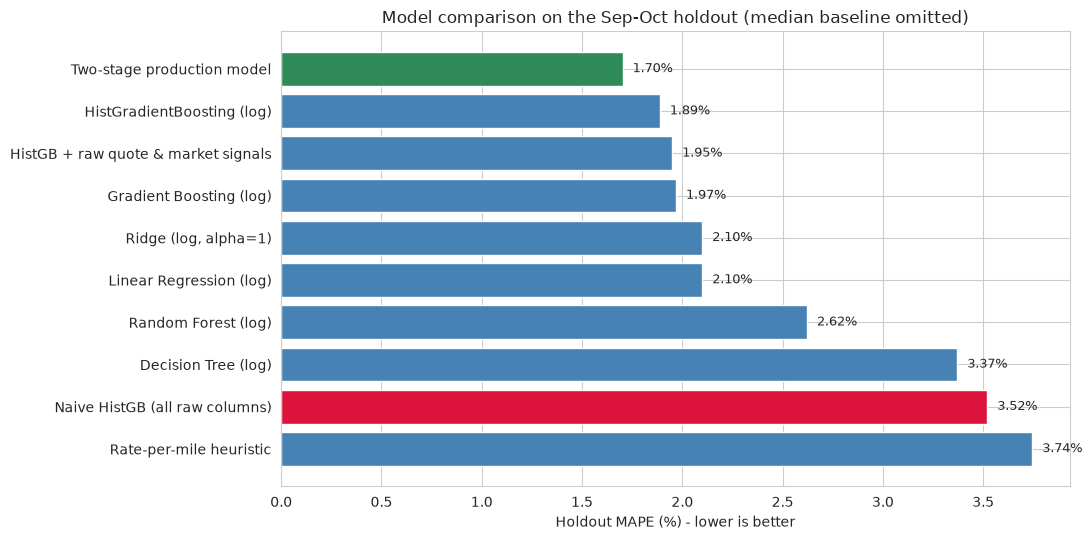

✅ Production pipeline ready for validation-strategy check and tuning


In [14]:
"""
Phase 4: Production Pipeline Construction

Demonstrates: Custom estimator, end-to-end pipeline, preprocessing integration
From Lecture: 11 (ML Pipelines)
"""

class TwoStageFreightRegressor(BaseEstimator, RegressorMixin):
    """
    log(rate) = lane_model(lane features) + linear market level(LEVEL_COLUMNS)

    lane_model   : any scikit-learn regressor (HistGradientBoostingRegressor here)
    level_columns: day-level columns handled by an ordinary least-squares model
    n_backfit    : number of back-fitting rounds (alternating fits of the two parts)
    """

    def __init__(self, lane_model=None, level_columns=LEVEL_COLUMNS, n_backfit=3):
        self.lane_model = lane_model
        self.level_columns = level_columns
        self.n_backfit = n_backfit

    def _split(self, X):
        X = pd.DataFrame(X)
        level_cols = list(self.level_columns)
        missing = [c for c in level_cols if c not in X.columns]
        if missing:
            raise ValueError(f"Missing market-level columns: {missing}")
        lane_cols = [c for c in X.columns if c not in level_cols]
        return X[lane_cols], X[level_cols]

    def fit(self, X, y):
        X_lane, X_level = self._split(X)
        y_log = np.log(np.asarray(y, dtype=float))
        template = self.lane_model if self.lane_model is not None else HistGradientBoostingRegressor(
            random_state=RANDOM_SEED)
        offset = np.zeros(len(y_log))
        self.backfit_history_ = []
        for _ in range(max(1, int(self.n_backfit))):
            lane = clone(template).fit(X_lane, y_log - offset)       # lane price given market level
            residual = y_log - lane.predict(X_lane)
            level = LinearRegression().fit(X_level, residual)          # market level given lane price
            offset = level.predict(X_level)
            self.backfit_history_.append(float(np.std(residual - offset)))
        self.lane_model_ = lane
        self.level_model_ = level
        self.lane_columns_ = list(X_lane.columns)
        return self

    def predict(self, X):
        check_is_fitted(self, ['lane_model_', 'level_model_'])
        X_lane, X_level = self._split(X)
        return np.exp(self.lane_model_.predict(X_lane[self.lane_columns_]) + self.level_model_.predict(X_level))

    def market_level_effects(self):
        """Human-readable market-level coefficients."""
        coef = dict(zip(self.level_columns, self.level_model_.coef_))
        return {
            'Trend per 30 days (%)': 100 * (np.exp(30 * coef['day_index']) - 1),
            'Market-index elasticity (% rate per 1% index)': coef['log_market_index_day'],
            'Quarter-end surge on the last day (%)': 100 * (np.exp(coef['quarter_end_ramp']) - 1),
        }


PRODUCTION_NAME = 'Two-stage production model'
production_pipeline = make_freight_pipeline(TwoStageFreightRegressor(lane_model=hgb()))

print("=" * 70)
print("🔧 PRODUCTION PIPELINE")
print("=" * 70)
print("\nPipeline Structure:")
for idx, (name, step) in enumerate(production_pipeline.steps, 1):
    print(f"  {idx}. {name}: {type(step).__name__}")
print(f"     └─ lane model : {type(production_pipeline.named_steps['model'].lane_model).__name__}")
print(f"     └─ market level: LinearRegression on {list(LEVEL_COLUMNS)}")

start = time.time()
production_pipeline.fit(X_dev, y_dev)
production_pred = production_pipeline.predict(X_hold)
production_metrics = regression_report(y_hold, production_pred)
two_stage = production_pipeline.named_steps['model']

print(f"\nTraining time: {time.time() - start:.0f}s | back-fitting residual std per round: "
      f"{[round(v, 4) for v in two_stage.backfit_history_]}")
print("\nHoldout performance (Sep-Oct):")
for metric, value in production_metrics.items():
    print(f"  • {metric:14s}: {value:,.3f}")
print("\nLearned market-level effects:")
for name, value in two_stage.market_level_effects().items():
    print(f"  • {name:46s}: {value:+.3f}")

results_df = pd.concat([results_df, pd.DataFrame([{'Model': PRODUCTION_NAME,
                                                   **production_metrics, 'Train Time (s)': time.time() - start}])],
                       ignore_index=True).sort_values('MAPE (%)').reset_index(drop=True)
results_df.to_csv(REPORT_DIR / 'baseline_results.csv', index=False)

fig, ax = plt.subplots(figsize=(11, 5.5))
plot_df = results_df[results_df['Model'] != 'Median baseline'].sort_values('MAPE (%)', ascending=False)
colors = ['crimson' if m == NAIVE_NAME else ('seagreen' if m == PRODUCTION_NAME else 'steelblue') for m in plot_df['Model']]
ax.barh(plot_df['Model'], plot_df['MAPE (%)'], color=colors)
for y_pos, value in enumerate(plot_df['MAPE (%)']):
    ax.text(value + 0.05, y_pos, f"{value:.2f}%", va='center', fontsize=9)
ax.set_xlabel('Holdout MAPE (%) - lower is better')
ax.set_title('Model comparison on the Sep-Oct holdout (median baseline omitted)')
plt.tight_layout()
save_figure(fig, '06_model_comparison.png')
plt.show()
print("✅ Production pipeline ready for validation-strategy check and tuning")

## 4.3 Validation Strategy Check — random K-fold vs time-based holdout

**Learning Connection:** Lecture 6 (Cross-Validation) & Lecture 9 (generalisation)

Three model designs, two ways of estimating their error:
1. **Random 5-fold CV** inside Jan–Aug (every month appears in both training and test folds).
2. **Time-based holdout** (train Jan–Aug → predict Sep–Oct), which is what the real task looks like.

A good validation strategy must rank the models the same way the future does.

Naive HistGB (all raw columns)         random CV 1.56%  |  time holdout 3.52%  (22s)


HistGB + raw quote & market signals    random CV 1.22%  |  time holdout 1.95%  (30s)


Two-stage production model             random CV 1.53%  |  time holdout 1.70%  (49s)



,Random 5-fold CV MAPE (%),Time holdout MAPE (%),Optimism (holdout / CV),Rank by random CV,Rank by time holdout
Model,,,,,
Naive HistGB (all raw columns),1.557,3.520,2.261,3,3
HistGB + raw quote & market signals,1.224,1.949,1.593,1,2
Two-stage production model,1.529,1.702,1.113,2,1


Random CV would choose : HistGB + raw quote & market signals
The future rewards     : Two-stage production model
➡️  Random K-fold picks the WRONG model - only the time-based split ranks them correctly.


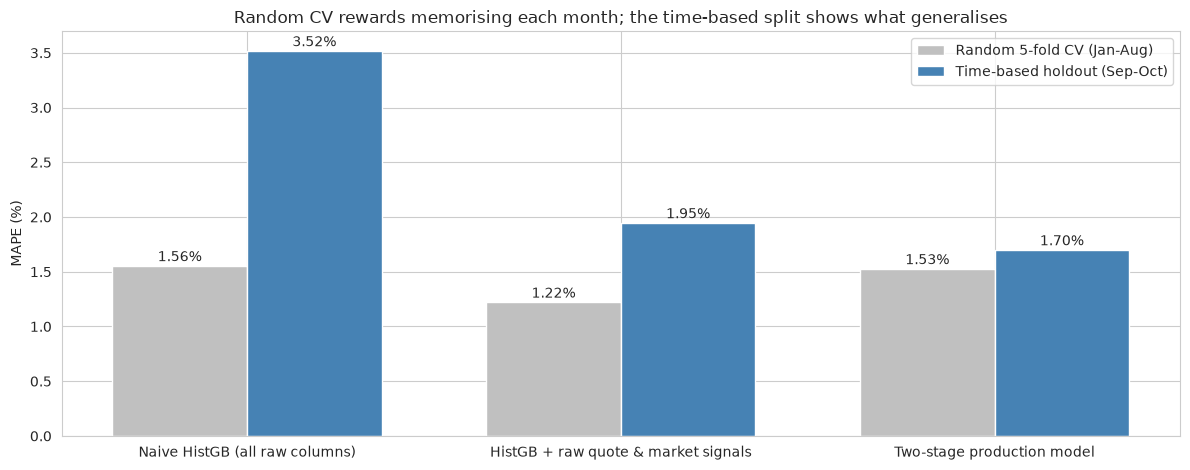

In [15]:
"""
Phase 4: Does the validation strategy tell the truth?

Demonstrates: Random K-fold vs temporal holdout, optimism of random CV under drift
From Lecture: 6 (Cross-Validation), 9 (Bias-Variance / generalisation)
"""

kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_SEED)
holdout_mape_of = lambda model_name: results_df.loc[results_df['Model'] == model_name, 'MAPE (%)'].iloc[0]
comparison = []
for name, pipeline, holdout_mape in [
        (NAIVE_NAME, baseline_models[NAIVE_NAME], holdout_mape_of(NAIVE_NAME)),
        (SIGNALS_NAME, baseline_models[SIGNALS_NAME], holdout_mape_of(SIGNALS_NAME)),
        (PRODUCTION_NAME, production_pipeline, production_metrics['MAPE (%)'])]:
    start = time.time()
    cv_pred = cross_val_predict(clone(pipeline), X_dev, y_dev, cv=kfold)
    cv_mape = 100 * mean_absolute_percentage_error(y_dev, cv_pred)
    comparison.append({'Model': name, 'Random 5-fold CV MAPE (%)': cv_mape,
                       'Time holdout MAPE (%)': holdout_mape,
                       'Optimism (holdout / CV)': holdout_mape / cv_mape})
    print(f"{name:38s} random CV {cv_mape:.2f}%  |  time holdout {holdout_mape:.2f}%  ({time.time() - start:.0f}s)")

validation_check = pd.DataFrame(comparison).set_index('Model')
validation_check['Rank by random CV'] = validation_check['Random 5-fold CV MAPE (%)'].rank().astype(int)
validation_check['Rank by time holdout'] = validation_check['Time holdout MAPE (%)'].rank().astype(int)
print("\n" + "=" * 70)
display(validation_check.round(3))
validation_check.to_csv(REPORT_DIR / 'validation_strategy_check.csv')

best_by_cv = validation_check['Random 5-fold CV MAPE (%)'].idxmin()
best_by_time = validation_check['Time holdout MAPE (%)'].idxmin()
print(f"Random CV would choose : {best_by_cv}")
print(f"The future rewards     : {best_by_time}")
if best_by_cv != best_by_time:
    print("➡️  Random K-fold picks the WRONG model - only the time-based split ranks them correctly.")

fig, ax = plt.subplots(figsize=(12, 4.8))
x = np.arange(len(validation_check))
ax.bar(x - 0.18, validation_check['Random 5-fold CV MAPE (%)'], width=0.36, label='Random 5-fold CV (Jan-Aug)', color='silver')
ax.bar(x + 0.18, validation_check['Time holdout MAPE (%)'], width=0.36, label='Time-based holdout (Sep-Oct)', color='steelblue')
for i, (cv_v, ho_v) in enumerate(zip(validation_check['Random 5-fold CV MAPE (%)'], validation_check['Time holdout MAPE (%)'])):
    ax.text(i - 0.18, cv_v + 0.04, f"{cv_v:.2f}%", ha='center')
    ax.text(i + 0.18, ho_v + 0.04, f"{ho_v:.2f}%", ha='center')
ax.set_xticks(x)
ax.set_xticklabels(validation_check.index)
ax.set_ylabel('MAPE (%)')
ax.set_title('Random CV rewards memorising each month; the time-based split shows what generalises')
ax.legend()
plt.tight_layout()
save_figure(fig, '07_validation_strategy.png')
plt.show()

**Conclusion — why the time-based split is the right validation**
* With random folds every month sits on both sides of the split, so a tree can learn *each month's* `quote_signal` regime and market level from neighbouring days. Under random CV the model with raw signals therefore looks **best**, and the fully naive model looks about as good as the production model.
* On genuinely future months the ranking changes: the production model is **best**, the raw-signal model is clearly worse, and the naive model's error more than **doubles**. The production model stays closest to its CV estimate (smallest optimism ratio).
* So random K-fold would have selected the wrong model and badly under-estimated the error of the naive one. All tuning therefore uses **time-series folds**, and the Sep–Oct holdout is the headline estimate.

## 4.4 Hyperparameter Tuning

**Learning Connection:** Lecture 10 (Hyperparameter Tuning)

`RandomizedSearchCV` over the lane model **and** a feature-engineering parameter (`ramp_days`), scored with **MAE on the two time-series folds** (Jan–Apr → May–Jun, Jan–Jun → Jul–Aug). The holdout is not used for selection.

In [16]:
"""
STEP 5: Hyperparameter Tuning (time-series cross-validation)

Demonstrates: RandomizedSearchCV on a pipeline, nested parameter names, temporal CV
From Lecture: 10 (Hyperparameter Tuning), 11 (Pipelines)
"""

param_distributions = {
    'features__ramp_days': [20, 25, 30],
    'model__lane_model__learning_rate': [0.03, 0.05, 0.08, 0.1],
    'model__lane_model__max_leaf_nodes': [31, 63, 127],
    'model__lane_model__min_samples_leaf': [10, 20, 40],
    'model__lane_model__l2_regularization': [0.0, 1.0, 5.0],
}

search = RandomizedSearchCV(
    estimator=make_freight_pipeline(TwoStageFreightRegressor(lane_model=hgb())),
    param_distributions=param_distributions,
    n_iter=8,
    cv=TIME_FOLDS,
    scoring='neg_mean_absolute_error',
    refit=True,
    random_state=RANDOM_SEED,
    n_jobs=N_JOBS,
)
start = time.time()
_ = search.fit(X_dev, y_dev)
print(f"Search finished in {time.time() - start:.0f}s ({search.n_iter} candidates x {len(TIME_FOLDS)} time folds)")

cv_results = pd.DataFrame(search.cv_results_)
cv_results['CV MAE ($)'] = -cv_results['mean_test_score']
cv_results['CV MAE std'] = cv_results['std_test_score']
top = cv_results.sort_values('rank_test_score')[['rank_test_score', 'CV MAE ($)', 'CV MAE std', 'params']].head(5)

print("\n📊 Hyperparameter Tuning Results (top 5)")
print("=" * 70)
display(top)
best_params = {k.split('__')[-1]: v for k, v in search.best_params_.items()}
print(f"Best parameters : {best_params}")
print(f"Best CV MAE     : ${-search.best_score_:,.2f}")

tuned_pipeline = search.best_estimator_                  # refit on all of Jan-Aug
tuned_pred = tuned_pipeline.predict(X_hold)
tuned_metrics = regression_report(y_hold, tuned_pred)
comparison_tuning = pd.DataFrame({'Default parameters': production_metrics, 'Tuned parameters': tuned_metrics}).T
print("\nDefault vs tuned on the untouched Sep-Oct holdout:")
display(comparison_tuning.round(3))

Search finished in 144s (8 candidates x 2 time folds)

📊 Hyperparameter Tuning Results (top 5)


,rank_test_score,CV MAE ($),CV MAE std,params
6,1,43.1146,2.2132,"{'model__lane_model__min_samples_leaf': 10, 'm..."
1,2,44.6238,3.6597,"{'model__lane_model__min_samples_leaf': 10, 'm..."
5,3,44.6508,3.4834,"{'model__lane_model__min_samples_leaf': 10, 'm..."
2,4,44.7138,3.6438,"{'model__lane_model__min_samples_leaf': 40, 'm..."
4,5,44.7484,3.7262,"{'model__lane_model__min_samples_leaf': 10, 'm..."


Best parameters : {'min_samples_leaf': 10, 'max_leaf_nodes': 63, 'learning_rate': 0.03, 'l2_regularization': 0.0, 'ramp_days': 30}
Best CV MAE     : $43.11



Default vs tuned on the untouched Sep-Oct holdout:


,MAE ($),RMSE ($),MAPE (%),MedAPE (%),R2,Within 5% (%)
Default parameters,38.896,56.282,1.702,1.439,0.998,97.814
Tuned parameters,38.443,55.560,1.680,1.417,0.998,97.857


## 4.5 Model Evaluation & Validation Analysis

**Learning Connection:** Lectures 7 (metrics), 9 (bias–variance) and 10 (model diagnostics)

Final holdout metrics, residual analysis, error by segment, a learning curve, permutation importance and an **unseen-city** stress test (12% of the validation loads involve a city the model has never seen).

📊 HOLDOUT PERFORMANCE (train Jan-Aug -> predict Sep-Oct)


,MAE ($),RMSE ($),MAPE (%),MedAPE (%),R2,Within 5% (%)
Clean labels,38.443,55.560,1.680,1.417,0.998,97.857
All labels (incl. flagged errors),94.491,629.919,4.199,1.441,0.830,96.377


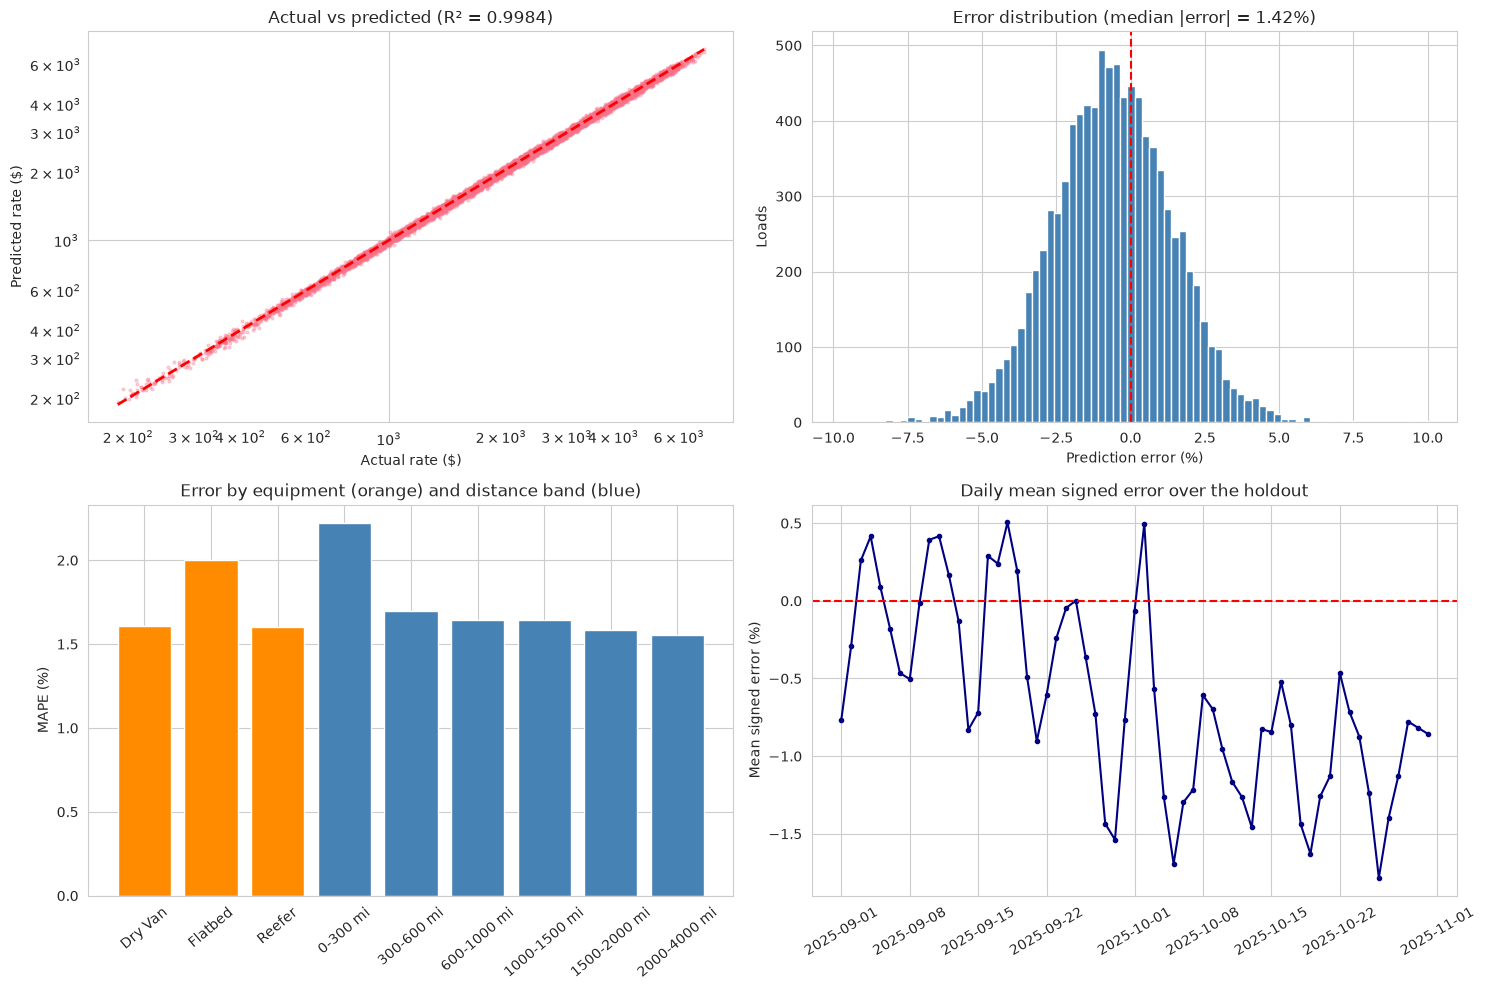

MAPE by month: {'Oct': 1.686, 'Sep': 1.674}
MAPE by equipment: {'Dry Van': 1.607, 'Flatbed': 2.001, 'Reefer': 1.605}
MAPE by distance band: {'0-300 mi': 2.221, '300-600 mi': 1.695, '600-1000 mi': 1.646, '1000-1500 mi': 1.642, '1500-2000 mi': 1.584, '2000-4000 mi': 1.554}
Mean signed error by month (%): {'Oct': -0.97, 'Sep': -0.26}
Mean signed error by weekday (%): from -1.23 (Sunday) to -0.10 (Thursday)


In [17]:
"""
STEP 6: Final Model Evaluation and Visualization

Demonstrates: Holdout metrics, residual analysis, segment errors
From Lecture: 7 (Metrics), 9 (Bias-Variance)
"""

evaluation_model = tuned_pipeline
hold_pred = evaluation_model.predict(X_hold)
hold_all_pred = evaluation_model.predict(holdout_all[FEATURE_COLUMNS])
final_holdout_metrics = regression_report(y_hold, hold_pred)
all_rows_metrics = regression_report(holdout_all[TARGET], hold_all_pred)

print("=" * 70)
print("📊 HOLDOUT PERFORMANCE (train Jan-Aug -> predict Sep-Oct)")
print("=" * 70)
display(pd.DataFrame({'Clean labels': final_holdout_metrics,
                      'All labels (incl. flagged errors)': all_rows_metrics}).T.round(3))

analysis = holdout.assign(predicted=hold_pred)
analysis['pct_error'] = 100 * (analysis['predicted'] - analysis[TARGET]) / analysis[TARGET]
analysis['abs_pct_error'] = analysis['pct_error'].abs()
analysis['distance_band'] = pd.cut(analysis['distance'], [0, 300, 600, 1000, 1500, 2000, 4000])
analysis['month_name'] = analysis['date'].dt.strftime('%b')

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
ax = axes[0, 0]
ax.scatter(analysis[TARGET], analysis['predicted'], s=4, alpha=0.3)
lims = [analysis[TARGET].min(), analysis[TARGET].max()]
ax.plot(lims, lims, 'r--', lw=2)
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Actual rate ($)')
ax.set_ylabel('Predicted rate ($)')
ax.set_title(f"Actual vs predicted (R² = {final_holdout_metrics['R2']:.4f})")

ax = axes[0, 1]
ax.hist(analysis['pct_error'].clip(-10, 10), bins=80, color='steelblue')
ax.axvline(0, color='red', linestyle='--')
ax.set_xlabel('Prediction error (%)')
ax.set_ylabel('Loads')
ax.set_title(f"Error distribution (median |error| = {analysis['abs_pct_error'].median():.2f}%)")

ax = axes[1, 0]
seg_eq = analysis.groupby('equipment')['abs_pct_error'].mean()
seg_d = analysis.groupby('distance_band', observed=True)['abs_pct_error'].mean()
labels = list(seg_eq.index) + [f"{int(b.left)}-{int(b.right)} mi" for b in seg_d.index]
values = list(seg_eq.values) + list(seg_d.values)
ax.bar(labels, values, color=['darkorange'] * len(seg_eq) + ['steelblue'] * len(seg_d))
ax.set_ylabel('MAPE (%)')
ax.set_title('Error by equipment (orange) and distance band (blue)')
ax.tick_params(axis='x', rotation=40)

ax = axes[1, 1]
daily_bias = analysis.groupby('date')['pct_error'].mean()
ax.plot(daily_bias.index, daily_bias.values, marker='.', color='navy')
ax.axhline(0, color='red', linestyle='--')
ax.set_ylabel('Mean signed error (%)')
ax.set_title('Daily mean signed error over the holdout')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
save_figure(fig, '08_holdout_diagnostics.png')
plt.show()

print("MAPE by month:", analysis.groupby('month_name')['abs_pct_error'].mean().round(3).to_dict())
print("MAPE by equipment:", seg_eq.round(3).to_dict())
print("MAPE by distance band:", {f"{int(b.left)}-{int(b.right)} mi": round(v, 3) for b, v in seg_d.items()})
print("Mean signed error by month (%):", analysis.groupby('month_name')['pct_error'].mean().round(2).to_dict())
weekday_bias = analysis.groupby(analysis['date'].dt.day_name())['pct_error'].mean()
print(f"Mean signed error by weekday (%): from {weekday_bias.min():+.2f} ({weekday_bias.idxmin()}) "
      f"to {weekday_bias.max():+.2f} ({weekday_bias.idxmax()})")

Learning curve computed in 51s
  train size  3,794: train MAE $21.9 | holdout MAE $47.4
  train size  9,486: train MAE $26.4 | holdout MAE $43.1
  train size 18,972: train MAE $25.4 | holdout MAE $40.5
  train size 28,458: train MAE $27.5 | holdout MAE $39.3
  train size 37,944: train MAE $28.5 | holdout MAE $38.4



Permutation importance computed in 16s (MAE increase in $ when a column is shuffled)
distance        1234.26
pickup_lon       153.99
delivery_lon     152.02
equipment        109.23
weight            38.53
delivery_lat      29.82
pickup_lat        29.75
date              11.46
quote_signal       0.00
market_index       0.00
delivery           0.00
pickup             0.00


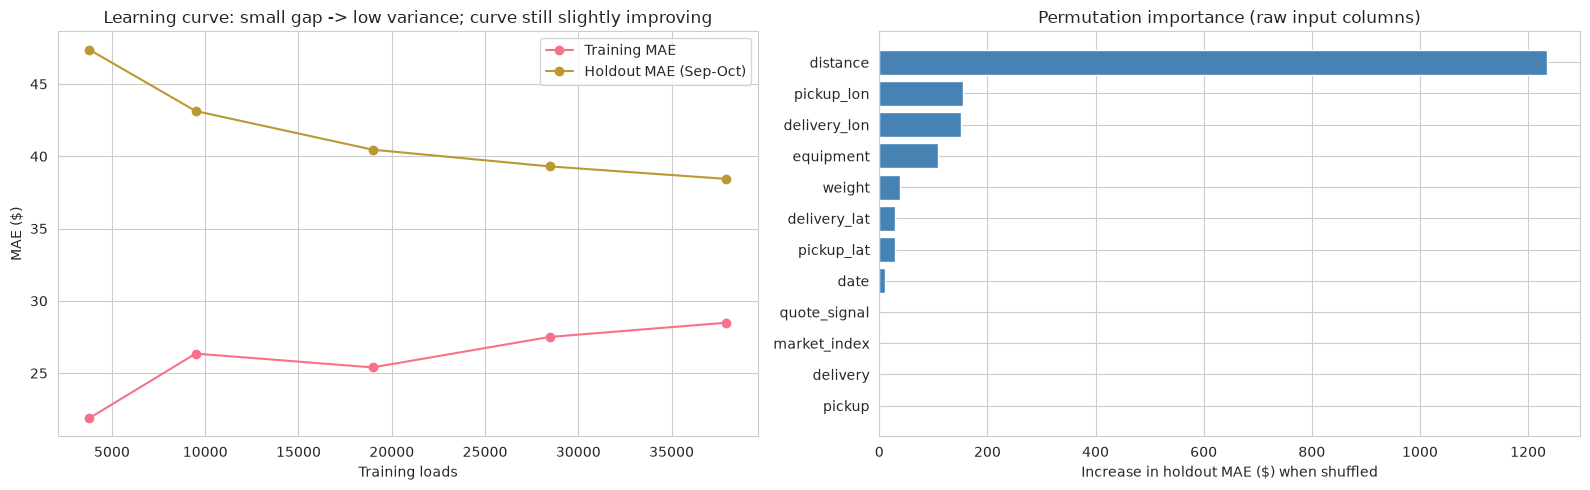


🧊 Unseen-city test: removed every training load touching [np.str_('Salt Lake City'), np.str_('Syracuse'), np.str_('Albany'), np.str_('New York'), np.str_('Bakersfield'), np.str_('Lubbock'), np.str_('Dallas'), np.str_('Chattanooga')]
   (8,862 training loads removed; 2,144 holdout loads touch those cities)
   • Loads touching an unseen city (MAPE %): 1.94%
   • Loads with known cities (MAPE %): 1.69%
   ➡️ Coordinate-based features generalise to new cities with only a small accuracy loss.


In [18]:
"""
Phase 4: Learning curve, permutation importance and unseen-city stress test

Demonstrates: Bias-variance diagnosis, model-agnostic feature importance, robustness check
From Lecture: 9 (Bias-Variance), 10 (Diagnostics)
"""

# --- Learning curve (bias-variance) -------------------------------------------------------
lc_X = pd.concat([X_dev, X_hold], ignore_index=True)
lc_y = pd.concat([y_dev, y_hold], ignore_index=True)
lc_split = [(np.arange(len(X_dev)), np.arange(len(X_dev), len(lc_X)))]
start = time.time()
train_sizes, train_scores, test_scores = learning_curve(
    clone(tuned_pipeline), lc_X, lc_y, cv=lc_split, train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0],
    scoring='neg_mean_absolute_error', shuffle=True, random_state=RANDOM_SEED, n_jobs=N_JOBS)
train_mae, test_mae = -train_scores.mean(axis=1), -test_scores.mean(axis=1)
print(f"Learning curve computed in {time.time() - start:.0f}s")
for n, tr_mae, te_mae in zip(train_sizes, train_mae, test_mae):
    print(f"  train size {n:>6,}: train MAE ${tr_mae:,.1f} | holdout MAE ${te_mae:,.1f}")

# --- Permutation importance on raw inputs (model-agnostic) --------------------------------
start = time.time()
perm = permutation_importance(tuned_pipeline, X_hold, y_hold, scoring='neg_mean_absolute_error',
                              n_repeats=3, random_state=RANDOM_SEED, n_jobs=N_JOBS)
importance = pd.Series(perm.importances_mean, index=X_hold.columns).sort_values()
print(f"\nPermutation importance computed in {time.time() - start:.0f}s (MAE increase in $ when a column is shuffled)")
print(importance.sort_values(ascending=False).round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
ax = axes[0]
ax.plot(train_sizes, train_mae, marker='o', label='Training MAE')
ax.plot(train_sizes, test_mae, marker='o', label='Holdout MAE (Sep-Oct)')
ax.set_xlabel('Training loads')
ax.set_ylabel('MAE ($)')
ax.set_title('Learning curve: small gap -> low variance; curve still slightly improving')
ax.legend()
ax = axes[1]
ax.barh(importance.index, importance.values, color=['grey' if v <= 0.5 else 'steelblue' for v in importance.values])
ax.set_xlabel('Increase in holdout MAE ($) when shuffled')
ax.set_title('Permutation importance (raw input columns)')
plt.tight_layout()
save_figure(fig, '09_learning_curve_importance.png')
plt.show()

# --- Unseen-city stress test --------------------------------------------------------------
rng = np.random.RandomState(RANDOM_SEED)
dev_cities = sorted(set(dev['pickup']) | set(dev['delivery']))
held_out_cities = list(rng.choice(dev_cities, size=8, replace=False))
keep = ~(dev['pickup'].isin(held_out_cities) | dev['delivery'].isin(held_out_cities))
cold_model = clone(tuned_pipeline).fit(X_dev[keep.values], y_dev[keep.values])
touches = (holdout['pickup'].isin(held_out_cities) | holdout['delivery'].isin(held_out_cities)).values
cold_pred = cold_model.predict(X_hold)
cold_start = {
    'Loads touching an unseen city (MAPE %)': 100 * mean_absolute_percentage_error(y_hold[touches], cold_pred[touches]),
    'Loads with known cities (MAPE %)': 100 * mean_absolute_percentage_error(y_hold[~touches], cold_pred[~touches]),
}
print(f"\n🧊 Unseen-city test: removed every training load touching {held_out_cities}")
print(f"   ({int((~keep).sum()):,} training loads removed; {int(touches.sum()):,} holdout loads touch those cities)")
for k, v in cold_start.items():
    print(f"   • {k}: {v:.2f}%")
print("   ➡️ Coordinate-based features generalise to new cities with only a small accuracy loss.")

**What the diagnostics show**
* **Errors are tight and symmetric** — median absolute error ≈ 1.4% and ≈ 98% of loads within ±5%. Flatbed is the hardest equipment (≈ 2.0% vs ≈ 1.6%), and short hauls under 300 miles have the highest *percentage* error (≈ 2.2%) because a few dollars are a larger share of a small rate.
* **Bias over time** — September is almost unbiased, October is under-predicted by about 1%: rates held up while `market_index` fell (Section 2.4.2), and a model trained only on Jan–Aug cannot know that yet. A small weekly ripple remains as well. This is exactly why Part 5 re-trains on Jan–Oct, so the trend has seen the Sep–Oct level before forecasting Nov–Dec.
* **Learning curve** — holdout MAE keeps falling as data is added and the gap to training error is moderate → the model is not over-fitting; more history would still help a little.
* **Permutation importance** — distance dominates, followed by geography (longitudes), equipment and weight; `date` carries the market level. Shuffling `quote_signal`, the load-level `market_index` or the city names changes nothing — the model does not use them (the daily market index comes from the date lookup).
* **Unseen cities** — loads touching a city removed from training are only slightly worse than loads between known cities, so the 1,447 validation loads with new cities are covered.

---

# PART 5: FINAL MODEL, PREDICTIONS & DEPLOYMENT

---

## 5.1 Final Training on all labelled months

**Learning Connection:** Lecture 11 (Production Pipelines)

The selected configuration (tuned hyper-parameters) is re-trained on **all clean labelled loads (Jan–Oct)** so the most recent market level is included before forecasting Nov–Dec.

In [19]:
"""
Phase 5: Final refit on Jan-Oct

Demonstrates: Refit selected pipeline on all available labelled data
From Lecture: 11 (Pipelines)
"""

final_model = clone(tuned_pipeline)                         # same hyper-parameters, untrained
start = time.time()
final_model.fit(dev_clean[FEATURE_COLUMNS], dev_clean[TARGET])
final_regressor = final_model.named_steps['model']

in_sample = regression_report(dev_clean[TARGET], final_model.predict(dev_clean[FEATURE_COLUMNS]))
print("=" * 70)
print("🏁 FINAL MODEL TRAINED")
print("=" * 70)
print(f"Training loads : {len(dev_clean):,} (Jan-Oct, clean labels) in {time.time() - start:.0f}s")
print(f"Parameters     : {best_params}")
print(f"In-sample MAPE : {in_sample['MAPE (%)']:.2f}%  (holdout estimate: {final_holdout_metrics['MAPE (%)']:.2f}%)")
print("\nMarket-level effects learned on Jan-Oct:")
for name, value in final_regressor.market_level_effects().items():
    print(f"  • {name:46s}: {value:+.3f}")

🏁 FINAL MODEL TRAINED
Training loads : 47,323 (Jan-Oct, clean labels) in 23s
Parameters     : {'min_samples_leaf': 10, 'max_leaf_nodes': 63, 'learning_rate': 0.03, 'l2_regularization': 0.0, 'ramp_days': 30}
In-sample MAPE : 1.26%  (holdout estimate: 1.68%)

Market-level effects learned on Jan-Oct:
  • Trend per 30 days (%)                         : +0.594
  • Market-index elasticity (% rate per 1% index) : +0.153
  • Quarter-end surge on the last day (%)         : +3.970


## 5.2 Label-free signal check on the validation months

Before predicting, the `quote_signal` decision is re-checked **without any labels**: if quote_signal still tracked rates in Nov–Dec it would correlate (±) with the model's predicted rate per mile, as it does in the training months.

,month,"corr(quote, model rate/mile)","corr(quote, actual rate/mile)",regime (label-free)
0,2025-01,0.988,0.996,DIRECT
1,2025-02,0.988,0.996,DIRECT
2,2025-03,0.988,0.997,DIRECT
3,2025-04,-0.984,-0.993,INVERTED
4,2025-05,-0.986,-0.994,INVERTED
5,2025-06,0.988,0.997,DIRECT
6,2025-07,-0.985,-0.994,INVERTED
7,2025-08,-0.022,-0.020,NOISE
8,2025-09,0.987,0.997,DIRECT
9,2025-10,-0.985,-0.994,INVERTED


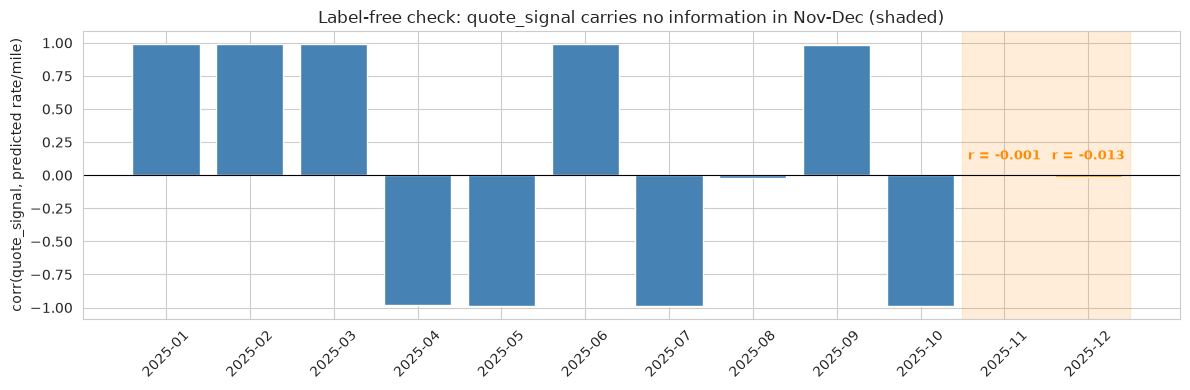

Nov-Dec correlation: [-0.001, -0.013] -> NOISE regime -> excluding quote_signal was the right call.


In [20]:
"""
Phase 5: Is quote_signal informative in Nov-Dec? (no labels needed)

Demonstrates: Monitoring feature drift on unlabelled scoring data
From Lecture: 6 (Validation), 9 (Generalisation)
"""

def quote_alignment(frame, label_rpm=None):
    pred_rpm = final_model.predict(frame[FEATURE_COLUMNS]) / frame['distance'].values
    tmp = pd.DataFrame({'period': frame['date'].dt.to_period('M').astype(str).values,
                        'quote': frame['quote_signal'].values, 'pred_rpm': pred_rpm})
    if label_rpm is not None:
        tmp['label_rpm'] = label_rpm
    rows = []
    for period, grp in tmp.groupby('period'):
        row = {'month': period, 'corr(quote, model rate/mile)': np.corrcoef(grp['quote'], grp['pred_rpm'])[0, 1]}
        row['corr(quote, actual rate/mile)'] = (np.corrcoef(grp['quote'], grp['label_rpm'])[0, 1]
                                                if label_rpm is not None else np.nan)
        rows.append(row)
    return pd.DataFrame(rows)

signal_check = pd.concat([
    quote_alignment(dev_clean, label_rpm=(dev_clean[TARGET] / dev_clean['distance']).values),
    quote_alignment(validation_raw)], ignore_index=True)
signal_check['regime (label-free)'] = np.where(signal_check['corr(quote, model rate/mile)'] > 0.5, 'DIRECT',
                                      np.where(signal_check['corr(quote, model rate/mile)'] < -0.5, 'INVERTED', 'NOISE'))
display(signal_check.round(3))

fig, ax = plt.subplots(figsize=(12, 4))
colors = ['darkorange' if m >= '2025-11' else 'steelblue' for m in signal_check['month']]
ax.bar(signal_check['month'], signal_check['corr(quote, model rate/mile)'], color=colors)
ax.axhline(0, color='black', lw=0.8)
n_months = len(signal_check)
ax.axvspan(n_months - 2.5, n_months - 0.5, color='darkorange', alpha=0.15)
for pos in (n_months - 2, n_months - 1):
    value = signal_check['corr(quote, model rate/mile)'].iloc[pos]
    ax.text(pos, 0.12, f"r = {value:.3f}", ha='center', fontsize=9, color='darkorange', fontweight='bold')
ax.set_ylabel('corr(quote_signal, predicted rate/mile)')
ax.set_title('Label-free check: quote_signal carries no information in Nov-Dec (shaded)')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
save_figure(fig, '10_quote_signal_validation_check.png')
plt.show()
nov_dec = signal_check[signal_check['month'] >= '2025-11']
print(f"Nov-Dec correlation: {nov_dec['corr(quote, model rate/mile)'].round(3).tolist()} -> NOISE regime "
      f"-> excluding quote_signal was the right call.")

## 5.3 Predict the 12,000 validation loads

**Learning Connection:** Lecture 11 (deployment) — the pipeline applies every cleaning step automatically.

In [21]:
"""
Phase 5: Validation predictions -> validation_predictions.csv

Demonstrates: Batch scoring with the persisted pipeline, output validation
From Lecture: 11 (Deployment)
"""

validation_pred = final_model.predict(validation_raw[FEATURE_COLUMNS])
prediction_by_id = pd.Series(validation_pred, index=validation_raw['load_id'].values)

submission = template_raw[['load_id']].copy()
submission['predicted_rate'] = submission['load_id'].map(prediction_by_id).round(2)

# Output checks (same rules as score.py)
assert list(submission.columns) == ['load_id', 'predicted_rate']
assert len(submission) == 12000 and submission['load_id'].is_unique
assert set(submission['load_id']) == set(validation_raw['load_id'])
assert submission['predicted_rate'].notna().all() and np.isfinite(submission['predicted_rate']).all()
assert (submission['predicted_rate'] > 0).all()

SUBMISSION_PATH = Path('validation_predictions.csv')
submission.to_csv(SUBMISSION_PATH, index=False)

print("=" * 70)
print("📦 VALIDATION PREDICTIONS SAVED")
print("=" * 70)
print(f"File: {SUBMISSION_PATH}  ({len(submission):,} rows, columns = {list(submission.columns)})")
display(submission.head())
print("Predicted rate summary:")
print(submission['predicted_rate'].describe().round(2))

check = validation_raw.assign(predicted_rate=validation_pred)
print("\nMedian predicted $/mile by month:",
      (check['predicted_rate'] / check['distance']).groupby(check['date'].dt.strftime('%b')).median().round(3).to_dict())
print(f"Median actual $/mile in Sep-Oct (clean): {np.median(holdout[TARGET] / holdout['distance']):.3f}")
new_city = check['pickup'].isin(NEW_CITIES) | check['delivery'].isin(NEW_CITIES)
print(f"Loads touching new cities: {int(new_city.sum()):,} - median $/mile "
      f"{np.median(check.loc[new_city, 'predicted_rate'] / check.loc[new_city, 'distance']):.3f} vs "
      f"{np.median(check.loc[~new_city, 'predicted_rate'] / check.loc[~new_city, 'distance']):.3f} for known cities")

📦 VALIDATION PREDICTIONS SAVED
File: validation_predictions.csv  (12,000 rows, columns = ['load_id', 'predicted_rate'])


,load_id,predicted_rate
0,TE-000001,845.73
1,TE-000002,5144.17
2,TE-000003,5241.63
3,TE-000004,3997.77
4,TE-000005,1881.66


Predicted rate summary:
count    12000.00
mean      2396.27
std       1382.00
min        198.52
25%       1293.40
50%       2076.37
75%       3398.58
max       6993.12
Name: predicted_rate, dtype: float64

Median predicted $/mile by month: {'Dec': 2.21, 'Nov': 2.15}
Median actual $/mile in Sep-Oct (clean): 2.162
Loads touching new cities: 1,447 - median $/mile 2.179 vs 2.182 for known cities


## 5.4 Fixed December chart inputs

The December file only contains `pickup, delivery, distance, equipment, weight, date`. The missing model inputs are filled from the leakage-free lookups: **city coordinates** (Lexington, Fort Wayne) and the **daily market index** for each December date (average across that day's validation loads). `quote_signal` is not used by the model. The file keeps its original seven columns and order, as `score.py` requires.

In [22]:
"""
Phase 5: Fill data/december_chart_inputs.csv

Demonstrates: Scoring incomplete inputs with documented lookups, model explanation
From Lecture: 11 (Deployment)
"""

december = december_raw.copy()
dec_inputs = december.drop(columns=['predicted_rate']).copy()
dec_inputs['date'] = pd.to_datetime(dec_inputs['date'])
for side in ('pickup', 'delivery'):
    dec_inputs[f'{side}_lat'] = dec_inputs[side].map(CITY_COORDS['lat'])
    dec_inputs[f'{side}_lon'] = dec_inputs[side].map(CITY_COORDS['lon'])
dec_inputs['market_index'] = dec_inputs['date'].map(MARKET_DAILY)
dec_inputs['quote_signal'] = np.nan                      # not available - not used by the model
assert dec_inputs[['pickup_lat', 'pickup_lon', 'delivery_lat', 'delivery_lon', 'market_index']].notna().all().all()

december['predicted_rate'] = final_model.predict(dec_inputs[FEATURE_COLUMNS]).round(2)
december.to_csv(DECEMBER_PATH, index=False)
assert list(pd.read_csv(DECEMBER_PATH).columns) == ['pickup', 'delivery', 'distance', 'equipment',
                                                    'weight', 'date', 'predicted_rate']

# Explain the curve: lane price x trend x market index x quarter-end surge
features_dec = final_model.named_steps['features'].transform(dec_inputs[FEATURE_COLUMNS])
coef = dict(zip(LEVEL_COLUMNS, final_regressor.level_model_.coef_))
lane_price = np.exp(final_regressor.lane_model_.predict(features_dec[final_regressor.lane_columns_])
                    + final_regressor.level_model_.intercept_)
explain = pd.DataFrame({
    'date': dec_inputs['date'].dt.strftime('%a %d %b'),
    'market_index_day': dec_inputs['market_index'].round(3),
    'quarter_end_ramp': features_dec['quarter_end_ramp'].round(2),
    'trend_effect_%': 100 * (np.exp(coef['day_index'] * features_dec['day_index']) - 1),
    'market_effect_%': 100 * (np.exp(coef['log_market_index_day'] * features_dec['log_market_index_day']) - 1),
    'quarter_end_effect_%': 100 * (np.exp(coef['quarter_end_ramp'] * features_dec['quarter_end_ramp']) - 1),
    'predicted_rate': december['predicted_rate'],
})
print("=" * 70)
print("📅 DECEMBER 2025 - Lexington -> Fort Wayne | 360 mi | Dry Van | 32,000 lb")
print("=" * 70)
print(f"Lane price before market effects: ${lane_price[0]:,.2f}")
display(explain.iloc[::3].round(2))
print(f"Range: ${december['predicted_rate'].min():,.2f} - ${december['predicted_rate'].max():,.2f} | "
      f"mean ${december['predicted_rate'].mean():,.2f}")
history = dev_clean[(dev_clean['pickup'] == 'Lexington') & (dev_clean['delivery'] == 'Fort Wayne') &
                    (dev_clean['equipment'] == 'Dry Van')]
lane_history = {'n': int(len(history)), 'median': float(history[TARGET].median()),
                'min': float(history[TARGET].min()), 'max': float(history[TARGET].max()),
                'median_distance': float(history['distance'].median())}
print(f"Historical Dry Van loads on this lane (Jan-Oct): {lane_history['n']} loads, "
      f"median ${lane_history['median']:,.2f} (range ${lane_history['min']:,.2f} - ${lane_history['max']:,.2f}) "
      f"at median {lane_history['median_distance']:.0f} mi")
weekday_market = dec_inputs.groupby(dec_inputs['date'].dt.day_name())['market_index'].mean().sort_values()
print(f"December market index by weekday: lowest {weekday_market.index[0]} ({weekday_market.iloc[0]:.3f}), "
      f"highest {weekday_market.index[-1]} ({weekday_market.iloc[-1]:.3f})")
print(f"Quarter-end ramp starts {int(final_model.named_steps['features'].ramp_days)} days before Dec 31 "
      f"(tuned ramp_days)")
print(f"✅ Saved: {DECEMBER_PATH}")

📅 DECEMBER 2025 - Lexington -> Fort Wayne | 360 mi | Dry Van | 32,000 lb
Lane price before market effects: $787.66


,date,market_index_day,quarter_end_ramp,trend_effect_%,market_effect_%,quarter_end_effect_%,predicted_rate
0,Mon 01 Dec,0.84,0.0,6.82,-2.73,0.00,818.38
3,Thu 04 Dec,1.02,0.1,6.88,0.36,0.39,848.22
6,Sun 07 Dec,0.83,0.2,6.94,-2.81,0.78,825.09
9,Wed 10 Dec,1.00,0.3,7.01,-0.02,1.17,852.61
12,Sat 13 Dec,0.90,0.4,7.07,-1.66,1.57,842.36
15,Tue 16 Dec,0.92,0.5,7.13,-1.20,1.97,850.09
18,Fri 19 Dec,0.99,0.6,7.20,-0.17,2.36,862.79
21,Mon 22 Dec,0.86,0.7,7.26,-2.29,2.76,848.31
24,Thu 25 Dec,1.04,0.8,7.32,0.67,3.16,877.94
27,Sun 28 Dec,0.86,0.9,7.39,-2.32,3.57,855.67


Range: $818.38 - $883.59 | mean $851.30
Historical Dry Van loads on this lane (Jan-Oct): 21 loads, median $807.89 (range $757.93 - $934.37) at median 362 mi
December market index by weekday: lowest Sunday (0.843), highest Thursday (1.032)
Quarter-end ramp starts 30 days before Dec 31 (tuned ramp_days)
✅ Saved: data/december_chart_inputs.csv


## 5.5 Run the provided `score.py`

`score.py` validates both output files and draws the official December chart (`scorer_results/candidate_december.png`).

$ python score.py --predictions validation_predictions.csv --december-predictions data/december_chart_inputs.csv


Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.



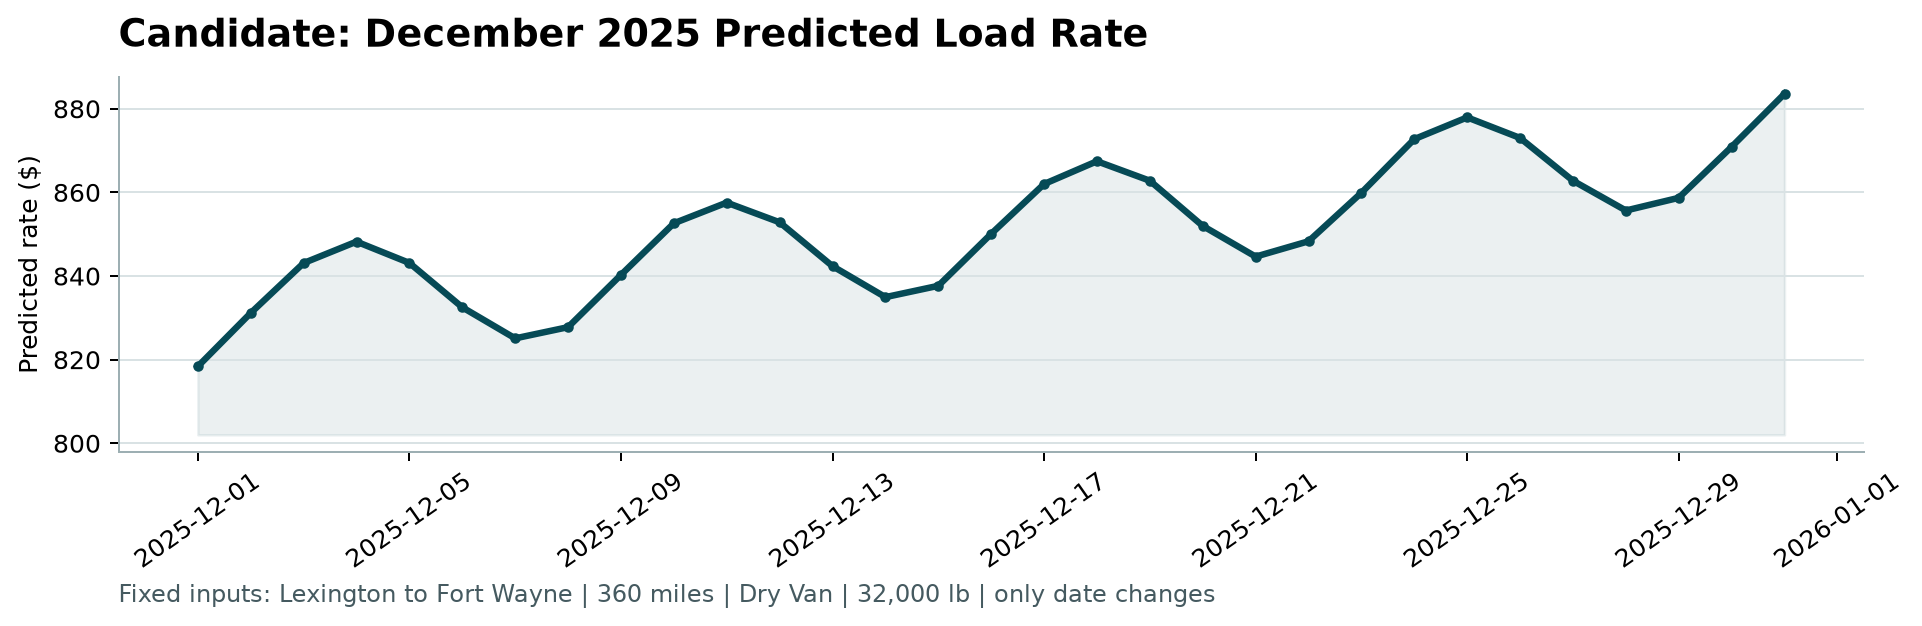

In [23]:
"""
Phase 5: Official validation + December chart via score.py
"""

SCORE_SCRIPT = Path('score.py')
CHART_PATH = Path('scorer_results') / 'candidate_december.png'
if SCORE_SCRIPT.is_file():
    command = [sys.executable, str(SCORE_SCRIPT), '--predictions', str(SUBMISSION_PATH),
               '--december-predictions', str(DECEMBER_PATH)]
    print('$ python ' + ' '.join(command[1:]))
    result = subprocess.run(command, capture_output=True, text=True)
    print(result.stdout)
    if result.returncode != 0:
        print(result.stderr)
        raise RuntimeError('score.py rejected the output files - see the message above.')
    display(Image(filename=str(CHART_PATH)))
else:
    print("ℹ️ score.py not found next to the notebook. Place the provided score.py in the project root and run:\n"
          "   python score.py --predictions validation_predictions.csv --december-predictions data/december_chart_inputs.csv")

**Reading the December chart**
* **Weekly cycle** — the daily market index is highest on Wednesday–Thursday and lowest on Sunday–Monday, so the predicted rate rises mid-week and dips around the weekend (elasticity ≈ 0.15, i.e. a 10% higher index adds ≈ 1.5%).
* **Quarter-end surge** — over the last `ramp_days` days of the quarter (tuned value printed in 5.4) the rate climbs ≈ 4% into Dec 31, the same pattern as at the end of March, June and September.
* **Slight upward trend** (≈ 0.6% per month) carried forward from Jan–Oct.
* **Level check** — the December values sit inside the range of the lane's historical Dry Van rates (printed in 5.4), slightly above their median because of the trend and the quarter-end surge — no extrapolation surprises.

## 5.6 Model persistence & run metrics

**Learning Connection:** Lecture 11/12 (joblib persistence)

In [24]:
"""
Phase 5: Persist the pipeline and the run metrics

Demonstrates: joblib persistence, reproducible reporting
From Lecture: 11 (Pipelines), 12 (Deployment)
"""

MODEL_PATH = MODEL_DIR / 'freight_rate_model.joblib'
joblib.dump(final_model, MODEL_PATH)
reloaded = joblib.load(MODEL_PATH)
assert np.allclose(reloaded.predict(validation_raw[FEATURE_COLUMNS].head(200)), validation_pred[:200])

run_metrics = {
    'versions': {'python': sys.version.split()[0], 'pandas': pd.__version__, 'numpy': np.__version__,
                 'scikit_learn': sklearn.__version__},
    'data': {'dev_rows': int(len(train_raw)), 'clean_rows': int(len(dev_clean)),
             'label_errors': int(dev_all['label_error'].sum()), 'validation_rows': int(len(validation_raw)),
             'new_validation_cities': NEW_CITIES, 'new_city_validation_rows': int(new_city_rows.sum())},
    'split': {'development': 'Jan 1 - Aug 31 2025 (clean)', 'holdout': 'Sep 1 - Oct 31 2025',
              'dev_rows': int(len(dev)), 'holdout_rows': int(len(holdout))},
    'best_params': {k: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else v)
                    for k, v in best_params.items()},
    'holdout_clean': {k: float(v) for k, v in final_holdout_metrics.items()},
    'holdout_all_labels': {k: float(v) for k, v in all_rows_metrics.items()},
    'validation_strategy_check': {k: {kk: float(vv) for kk, vv in row.items()}
                                  for k, row in validation_check.to_dict(orient='index').items()},
    'cold_start': {k: float(v) for k, v in cold_start.items()},
    'holdout_bias_by_month_pct': {str(k): float(v) for k, v in
                                  analysis.groupby('month_name')['pct_error'].mean().items()},
    'market_level_effects_final': {k: float(v) for k, v in final_regressor.market_level_effects().items()},
    'december': {'min': float(december['predicted_rate'].min()), 'max': float(december['predicted_rate'].max()),
                 'mean': float(december['predicted_rate'].mean())},
    'lane_history': lane_history,
    'quote_signal_label_free_corr': {str(month): float(corr) for month, corr in
                                     zip(signal_check['month'], signal_check['corr(quote, model rate/mile)'])},
    'validation_predictions': {'rows': int(len(submission)), 'mean': float(submission['predicted_rate'].mean()),
                               'median': float(submission['predicted_rate'].median())},
}
with open(REPORT_DIR / 'metrics.json', 'w') as fh:
    json.dump(run_metrics, fh, indent=2, default=str)

print("=" * 70)
print("💾 ARTIFACTS SAVED")
print("=" * 70)
for path in [SUBMISSION_PATH, DECEMBER_PATH, CHART_PATH, MODEL_PATH, REPORT_DIR / 'metrics.json',
             REPORT_DIR / 'baseline_results.csv', REPORT_DIR / 'data_quality_log.csv']:
    status = '✅' if Path(path).is_file() else '—'
    print(f"  {status} {path}")
print(f"\nFigures: {sorted(p.name for p in FIG_DIR.glob('*.png'))}")

💾 ARTIFACTS SAVED
  ✅ validation_predictions.csv
  ✅ data/december_chart_inputs.csv
  ✅ scorer_results/candidate_december.png
  ✅ outputs/models/freight_rate_model.joblib
  ✅ outputs/reports/metrics.json
  ✅ outputs/reports/baseline_results.csv
  ✅ outputs/reports/data_quality_log.csv

Figures: ['01_eda_overview.png', '02_label_errors.png', '03_quote_signal_regimes.png', '04_market_level.png', '05_time_split.png', '06_model_comparison.png', '07_validation_strategy.png', '08_holdout_diagnostics.png', '09_learning_curve_importance.png', '10_quote_signal_validation_check.png']


---

## 📝 Project Summary

### Phases completed
1. ✅ **Environment setup** — reproducible configuration and folder structure
2. ✅ **Data acquisition** — 4 files loaded with robust path handling
3. ✅ **Data-quality audit** — sign errors, missing values, caps/floors, unseen cities
4. ✅ **EDA** — pricing structure, outliers, **signal stability over time**
5. ✅ **Cleaning** — corrupted labels removed, every fix applied inside the pipeline
6. ✅ **Time-based split** — Jan–Aug development, Sep–Oct holdout, time-series tuning folds
7. ✅ **Feature engineering** — `FreightFeatureEngineer` custom transformer
8. ✅ **Baselines** — heuristic + 9 models compared on future months
9. ✅ **Production pipeline** — two-stage *lane price × market level* model
10. ✅ **Tuning & diagnostics** — RandomizedSearchCV, learning curve, importance, unseen-city test
11. ✅ **Deployment** — predictions, December chart via `score.py`, persisted model

### Key findings
| Finding | Evidence | Action |
|---------|----------|--------|
| ~1.4% of labels are 2–6× off | Bimodal robust residuals with an empty gap | Removed from training |
| `quote_signal` flips direct → inverted → noise by month | Monthly correlations of +0.99 / −0.99 / 0 | Excluded; Nov–Dec confirmed as noise (label-free) |
| `market_index` co-moves with rates Jan–Aug, not Sep–Oct | Daily market-level analysis | Daily average, linear elasticity + trend |
| Rates surge ~4% before every quarter end | Daily rate-level profile | `quarter_end_ramp` feature |
| 12% of validation loads involve unseen cities | City coverage check | Coordinate features; unseen-city test |
| Random CV ranks models wrongly under drift | Raw-signal model is best by random CV but worse than production on future months; naive model ~1.6% CV vs ~3.5% on future months | Time-based validation everywhere |

### Concepts applied from each lecture
| Lecture | Concept | Implementation |
|---------|---------|----------------|
| L2 | Data collection | Robust loading of 4 files |
| L3 | Preprocessing | Sign errors, imputation, label-error removal |
| L4 | EDA | Statistics, visual suite, outliers, signal stability |
| L5 | Feature engineering | Geography, circuity, weight, market calendar |
| L6 | Train-test split & CV | Time-based holdout, expanding-window folds |
| L7 | Regression metrics | MAE, RMSE, MAPE, R², within-5% |
| L9 | Bias–variance | Learning curve, random-CV optimism |
| L10 | Hyperparameter tuning | RandomizedSearchCV on time folds |
| L11 | Pipelines | Custom transformer + custom two-stage estimator, joblib |

### Limitations & next steps
* Nov–Dec holiday effects (Thanksgiving, Christmas) cannot be learned from Jan–Oct data; more history would help.
* The market-level trend is linear; with more than one year of data an explicit annual seasonality term should replace it.
* In production the daily market index would come from a market feed and the label-error detector would run as a monitoring job.

In [25]:
"""
Final summary of the run (printed from the actual results)
"""
print("=" * 70)
print("🎉 FREIGHT RATE PROJECT COMPLETE - SUBMISSION FILES READY")
print("=" * 70)
print(f"Final model      : Two-stage lane price (HistGradientBoosting) x market level (linear)")
print(f"Holdout (Sep-Oct): MAPE {final_holdout_metrics['MAPE (%)']:.2f}% | MAE ${final_holdout_metrics['MAE ($)']:,.2f} | "
      f"RMSE ${final_holdout_metrics['RMSE ($)']:,.2f} | R² {final_holdout_metrics['R2']:.4f} | "
      f"{final_holdout_metrics['Within 5% (%)']:.1f}% of loads within ±5%")
naive_row = validation_check.loc[NAIVE_NAME]
print(f"Naive model      : random CV {naive_row['Random 5-fold CV MAPE (%)']:.2f}% vs future months "
      f"{naive_row['Time holdout MAPE (%)']:.2f}% (why the time split matters)")
print(f"Model choice     : random CV would pick '{best_by_cv}', the time split picks '{best_by_time}'")
print(f"December chart   : ${december['predicted_rate'].min():,.2f} - ${december['predicted_rate'].max():,.2f}")
print("\nSubmit:")
print("  1. validation_predictions.csv")
print("  2. data/december_chart_inputs.csv (completed) + scorer_results/candidate_december.png")
print("  3. Report (PDF/DOCX) with the validation approach and the December chart")
print("  4. This notebook + requirements.txt + README.md in the GitHub repository")

🎉 FREIGHT RATE PROJECT COMPLETE - SUBMISSION FILES READY
Final model      : Two-stage lane price (HistGradientBoosting) x market level (linear)
Holdout (Sep-Oct): MAPE 1.68% | MAE $38.44 | RMSE $55.56 | R² 0.9984 | 97.9% of loads within ±5%
Naive model      : random CV 1.56% vs future months 3.52% (why the time split matters)
Model choice     : random CV would pick 'HistGB + raw quote & market signals', the time split picks 'Two-stage production model'
December chart   : $818.38 - $883.59

Submit:
  1. validation_predictions.csv
  2. data/december_chart_inputs.csv (completed) + scorer_results/candidate_december.png
  3. Report (PDF/DOCX) with the validation approach and the December chart
  4. This notebook + requirements.txt + README.md in the GitHub repository
